# Sprints 1 a 5 en un solo cuaderno
**Proyecto:** Modelo Predictivo de Segmentación de Mercado y Propensión a la Matrícula · Unicervantes

Este cuaderno reúne, en orden, los cuadernos de los Sprints 1 a 5 para ejecutarlos de una sola vez:
- La **preparación** (librerías, módulos y conexión segura) se hace **una sola vez**, al inicio.
- Los **datos** se cargan una vez al comenzar el Sprint 2 y los **modelos finales**, una vez al comenzar el Sprint 4.
- Cada sprint empieza con la marca **COMIENZA EL SPRINT N** y termina con **FIN DEL SPRINT N**.

| Sprint | Tema | Entrega |
|---|---|---|
| 1 | Definición del problema, datos y análisis exploratorio | jueves 22 de octubre de 2026 |
| 2 | Ingeniería de características y regresión logística | jueves 29 de octubre de 2026 |
| 3 | Modelado: regresión logística con el NLP, frente a Poisson, binomial negativa, Random Forest y XGBoost | jueves 5 de noviembre de 2026 |
| 4 | Machine Learning explicable con SHAP y LIME | jueves 12 de noviembre de 2026 |
| 5 | Validación con datos no vistos e impacto comercial | jueves 19 de noviembre de 2026 |

# Preparación (una sola vez)
Estas celdas dejan listo el entorno para los Sprints 1 a 5: rutas del proyecto, librerías y la conexión segura con
Supabase (las credenciales se leen del archivo `.env` o de los Secretos de Colab; nunca se escriben aquí).

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repositorio: se sube de carpeta hasta encontrar config/reglas_negocio.yaml
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "reglas_negocio.yaml").exists())
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
EN_COLAB = False
SPRINTS = RAIZ / "sprints"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

In [3]:
# Conexión segura del Sprint 1 (el mismo código de src/conexion_supabase.py)
from conexion_supabase import (TABLA, TIEMPO_LIMITE_S, crear_cliente, leer_dataset_matricula, obtener_credenciales,
                               probar_solo_lectura)

pd.set_option("display.max_columns", 60)        # el Sprint 1 muestra las 49 columnas del dataset plano
CSV_RESPALDO = RAIZ / "data" / "processed" / "dataset_matricula.csv"   # respaldo del Sprint 1 sin conexión

---
**COMIENZA EL SPRINT 1** · entrega del jueves 22 de octubre de 2026 · archivos del sprint en `notebooks/ · src/ · sql/ · docs/`

# Sprint 1 — Conexión segura con Supabase, dataset plano y EDA inicial
**Proyecto:** Modelo Predictivo de Segmentación de Mercado y Propensión a la Matrícula · Unicervantes
(Ingeniería en Analítica de Datos e Ingeniería en Sistemas de Software e IA).

Este cuaderno cubre los tres entregables que pidió el docente para el Sprint 1:

| # | Entregable | Sección |
|---|---|---|
| 1 | Conexión funcional entre Python y Supabase con buenas prácticas de seguridad | 1 |
| 2 | Un único dataset plano con las variables principales para predecir la matrícula | 2 |
| 3 | Inicio del EDA: estadística descriptiva, distribuciones y tratamiento preliminar de nulos | 3 |

> **Sobre los datos.** Los puntajes Saber 11, el colegio, el estrato, el género y la edad de cada aspirante son
> registros **reales** y anónimos del ICFES (datos abiertos). Nombres, proceso comercial, notas del colegio y
> resultado de matrícula son **sintéticos**, generados con reglas y supuestos documentados en el repositorio.

## 1. Conexión segura con Supabase
**Cómo se protegen las credenciales**
- La URL y la clave **no están en el código**: se leen del archivo `.env` (en el computador, excluido por
  `.gitignore`) o de los **Secretos de Colab**. El código nunca las imprime.
- Se usa la clave **publicable**, no la secreta. En la base, la seguridad a nivel de fila (RLS) le permite **solo
  leer** las tablas planas (`dataset_matricula` y `dataset_entrevista`); las 27 tablas transaccionales están cerradas
  para la API.
- Si la clave se filtrara, solo serviría para leer este dataset anonimizado: no permite escribir ni ver datos
  personales.

**Prueba:** se leen todas las filas (la API entrega máximo 1.000 por petición, por eso se lee en páginas) y se
intenta modificar la tabla con la misma clave. La base debe rechazarlo.

In [4]:
ORIGEN_RESPALDO = "copia del repositorio (data/processed, la que exporta el pipeline)"


def cargar_respaldo(tabla: str = "dataset_matricula") -> pd.DataFrame:
    """Sin conexión a Supabase: la misma tabla exportada por el pipeline, en data/processed del repositorio."""
    return pd.read_csv(Path(CSV_RESPALDO).with_name(f"{tabla}.csv"))

In [5]:
def motivo(error: Exception) -> str:
    """Explica el fallo sin mostrar nunca la URL ni la clave."""
    nombre = type(error).__name__
    if isinstance(error, RuntimeError):
        return str(error)
    if "Timeout" in nombre:
        return f"Supabase no respondió en {TIEMPO_LIMITE_S} s: revise la conexión a internet."
    if "Connect" in nombre:
        return "No se pudo llegar al servidor: revise SUPABASE_URL y la conexión a internet."
    codigo = getattr(error, "code", "")
    if codigo in ("PGRST301", "401") or "JWT" in str(getattr(error, "message", "")) or "API key" in str(error):
        return "La clave fue rechazada: revise que SUPABASE_KEY sea la clave publicable del proyecto."
    return f"{nombre}: revise la URL, la clave y la red."


cliente = None
try:
    print("Paso 1/3: leyendo las credenciales (en Colab, acepte el aviso de acceso a los secretos si aparece)…", flush=True)
    url, clave = obtener_credenciales()                      # de .env o de los Secretos; no se muestran
    print("Paso 2/3: conectando con la API de Supabase…", flush=True)
    cliente = crear_cliente(url, clave)
    df = leer_dataset_matricula(cliente)
    del url, clave
    print("Paso 3/3: probando que la clave NO pueda escribir…", flush=True)
    rechazada = probar_solo_lectura(cliente)
    ORIGEN = "Supabase (API de solo lectura)"
    print(f"\nConexión exitosa: {len(df):,} filas y {df.shape[1]} columnas leídas de la tabla '{TABLA}'.")
    print("Prueba de escritura con la misma clave:",
          "RECHAZADA por la base (permiso denegado). La clave solo puede leer." if rechazada
          else "NO fue rechazada: revisar las políticas RLS.")
except Exception as error:
    cliente = None
    print(f"\nNo se usó Supabase: {motivo(error)}")
    print(f"Se lee la misma tabla desde la {ORIGEN_RESPALDO} (no hay que subir ningún archivo).", flush=True)
    df, ORIGEN = cargar_respaldo(), ORIGEN_RESPALDO
    print(f"{len(df):,} filas y {df.shape[1]} columnas leídas.")
print("Origen de los datos:", ORIGEN)

Paso 1/3: leyendo las credenciales (en Colab, acepte el aviso de acceso a los secretos si aparece)…


Paso 2/3: conectando con la API de Supabase…


Paso 3/3: probando que la clave NO pueda escribir…



Conexión exitosa: 2,991 filas y 49 columnas leídas de la tabla 'dataset_matricula'.
Prueba de escritura con la misma clave: RECHAZADA por la base (permiso denegado). La clave solo puede leer.
Origen de los datos: Supabase (API de solo lectura)


## 2. Dataset plano para el modelo de matrícula
La base de datos tiene dos capas:
- **Capa transaccional (OLTP):** 27 tablas normalizadas que registran el proceso de admisión. Es la fuente.
- **Capa analítica (OLAP):** la tabla **`dataset_matricula`**, ya consolidada en Supabase. Tiene **una fila por
  inscrito** y una columna por variable. La **distancia al campus** viene calculada. Las notas del colegio no entran:
  dejaron de ser variables del análisis y quedan solo en la capa transaccional.
  Python no necesita unir tablas.

Roles de las columnas:
- **Control** (no son predictores): `inscripcion_id`, `periodo`, `conjunto`.
- **Objetivo:** `matriculado` (1 = pagó la matrícula del primer semestre).
- **Predictores:** el resto. Se excluyeron los datos personales y las variables con **fuga de datos** (por ejemplo,
  documentos entregados o forma de financiación, que solo se conocen al matricularse).

`conjunto` separa el histórico con resultado (`ENTRENAMIENTO`, 2024-1 a 2026-2) de la campaña abierta
(`CAMPANA_2027_1`), cuyo resultado aún no existe y es lo que el modelo predecirá.

In [6]:
CONTROL = ["inscripcion_id", "periodo", "conjunto"]
OBJETIVO = "matriculado"
NUMERICAS = ["edad_al_inscribirse", "estrato", "distancia_campus_km", "distancia_vial_km", "dias_registro_a_inscripcion",
             "contactos_antes_de_inscribirse", "colegio_promedio_saber11", "anios_desde_saber11",
             "punt_lectura_critica", "punt_matematicas", "punt_sociales", "punt_ciencias", "punt_ingles", "punt_global",
             "puntaje_vocacional",
             "pct_descuento_inicial", "pct_descuento_adicional", "valor_semestre_bruto", "valor_neto_primer_semestre"]
BINARIAS = ["captado_en_evento", "colegio_en_convenio", "entrevista_realizada", "cumple_req_saber11",
            "cumple_req_mi_vocacion", "elegible_foes", "apoyo_foes", "elegible_icetex", "aplica_icetex"]
CATEGORICAS = ["programa", "genero", "nacionalidad", "estado_civil", "regimen_salud", "tipo_ubicacion", "ciudad",
               "departamento", "canal", "asesor_id", "colegio_naturaleza", "colegio_caracter", "colegio_bilingue",
               "tipo_colegio", "colegio_nivel", "beca", "tipo_descuento"]
PREDICTORES = NUMERICAS + BINARIAS + CATEGORICAS
assert sorted(CONTROL + [OBJETIVO] + PREDICTORES) == sorted(df.columns), "Columnas inesperadas en el dataset"

# Tipos: la API devuelve JSON; los enteros con vacíos se guardan como Int64 (no como 1.0 / 0.0)
for c in [OBJETIVO, "puntaje_vocacional"]:
    df[c] = pd.to_numeric(df[c]).astype("Int64")
for c in NUMERICAS + BINARIAS:
    df[c] = pd.to_numeric(df[c])
df["asesor_id"] = df["asesor_id"].astype(str)
df = df.sort_values("inscripcion_id").reset_index(drop=True)

print(f"Forma: {df.shape[0]:,} filas × {df.shape[1]} columnas · {len(NUMERICAS)} numéricas, "
      f"{len(BINARIAS)} binarias, {len(CATEGORICAS)} categóricas, 1 objetivo y {len(CONTROL)} de control")
df.head()

Forma: 2,991 filas × 49 columnas · 19 numéricas, 9 binarias, 17 categóricas, 1 objetivo y 3 de control


,inscripcion_id,periodo,programa,conjunto,matriculado,genero,edad_al_inscribirse,estrato,nacionalidad,estado_civil,regimen_salud,tipo_ubicacion,ciudad,departamento,distancia_campus_km,distancia_vial_km,canal,captado_en_evento,asesor_id,dias_registro_a_inscripcion,contactos_antes_de_inscribirse,colegio_naturaleza,colegio_caracter,colegio_bilingue,tipo_colegio,colegio_nivel,colegio_promedio_saber11,colegio_en_convenio,anios_desde_saber11,punt_lectura_critica,punt_matematicas,punt_sociales,punt_ciencias,punt_ingles,punt_global,entrevista_realizada,puntaje_vocacional,cumple_req_saber11,cumple_req_mi_vocacion,beca,pct_descuento_inicial,valor_semestre_bruto,valor_neto_primer_semestre,elegible_foes,apoyo_foes,tipo_descuento,pct_descuento_adicional,elegible_icetex,aplica_icetex
0,1,2026-1,AD,ENTRENAMIENTO,0,M,16,1,COLOMBIA,SOLTERO,CONTRIBUTIVO,MUNICIPIO,Cota,CUNDINAMARCA,4.410,6.050,COLEGIO_CONVENIO,0,2,51,5,PRIVADO,ACADÉMICO,NaN,PRIVADO,MEDIO,272.100,1,0,69,73,59,59,65,325,1,4,1,1,SABER_11,0.350,4914000,3194100,0,0,NaN,0.000,1,0
1,2,2025-1,AD,ENTRENAMIENTO,0,F,16,4,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,8.190,10.810,LLAMADA_WHATSAPP,0,5,31,6,PRIVADO,ACADÉMICO,NO,PRIVADO,ALTO,305.900,0,0,66,59,52,56,77,298,1,2,0,0,NINGUNA,0.000,4658000,4658000,0,0,NaN,0.000,1,0
2,3,2025-2,AD,ENTRENAMIENTO,0,M,21,3,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,9.930,13.100,LLAMADA_WHATSAPP,0,1,15,5,PRIVADO,NaN,NaN,PRIVADO,BAJO,222.300,0,4,54,43,36,50,47,229,1,3,0,1,NINGUNA,0.000,4658000,4658000,0,0,NaN,0.000,0,0
3,4,2026-2,AD,ENTRENAMIENTO,0,M,18,2,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,5.070,6.400,CAMPUS_DAY,1,3,10,2,OFICIAL,ACADÉMICO,NO,OFICIAL,BAJO,254.700,0,0,56,53,47,50,47,256,0,<NA>,0,0,NINGUNA,0.000,4914000,4914000,0,0,NaN,0.000,1,0
4,5,2026-2,AD,ENTRENAMIENTO,1,M,18,3,COLOMBIA,SOLTERO,CONTRIBUTIVO,LOCALIDAD,Bogotá D.C.,BOGOTÁ D.C.,6.670,8.790,INMERSION,0,4,6,1,PRIVADO,ACADÉMICO,NO,PRIVADO,ALTO,307.900,0,1,71,72,64,65,71,341,1,4,1,1,SABER_11,0.450,4914000,2702700,0,0,FAMILIAR_ESTUDIANTE,0.100,1,0


In [7]:
rol = {**{c: "control" for c in CONTROL}, OBJETIVO: "objetivo", **{c: "numérica" for c in NUMERICAS},
       **{c: "binaria 0/1" for c in BINARIAS}, **{c: "categórica" for c in CATEGORICAS}}
resumen = pd.DataFrame({"rol": pd.Series(rol), "tipo_python": df.dtypes.astype(str),
                        "valores_distintos": df.nunique(), "nulos": df.isna().sum(),
                        "pct_nulos": (df.isna().mean() * 100).round(1)}).loc[df.columns]
display(resumen)

chequeos = {
    "inscripcion_id sin duplicados": df["inscripcion_id"].is_unique,
    "distancia al campus calculada en todas las filas": df["distancia_campus_km"].notna().all(),
    "objetivo vacío solo en la campaña 2027-1": (df[OBJETIVO].isna() == (df["conjunto"] == "CAMPANA_2027_1")).all(),
}
for nombre, ok in chequeos.items():
    print(("✔ " if ok else "✘ ") + nombre)
print("\nFilas por conjunto:", df["conjunto"].value_counts().to_dict())

,rol,tipo_python,valores_distintos,nulos,pct_nulos
inscripcion_id,control,int64,2991,0,0.000
periodo,control,str,7,0,0.000
programa,categórica,str,2,0,0.000
conjunto,control,str,2,0,0.000
matriculado,objetivo,Int64,2,416,13.900
genero,categórica,str,2,0,0.000
edad_al_inscribirse,numérica,int64,16,0,0.000
estrato,numérica,int64,6,0,0.000
nacionalidad,categórica,str,3,0,0.000
estado_civil,categórica,str,3,0,0.000


✔ inscripcion_id sin duplicados
✔ distancia al campus calculada en todas las filas
✔ objetivo vacío solo en la campaña 2027-1

Filas por conjunto: {'ENTRENAMIENTO': 2575, 'CAMPANA_2027_1': 416}


### 2.1 La entrevista vocacional en la base de datos
El formulario de **entrevista de admisión** de Unicervantes tiene preguntas abiertas. Se guardan las de tres
secciones: **Interés por el programa académico** (5 preguntas), **Historia de vida** (7) e **Interés por la
universidad** (1).

Esquema relacional (capa transaccional, cerrada a la API):

```
inscripcion (1) ──< (0..1) entrevista_admision (1) ──< (13) respuesta_entrevista (n) >── (1) pregunta_entrevista
   inscripcion_id            inscripcion_id PK, FK          inscripcion_id + pregunta_id PK       pregunta_id PK
   puntaje_vocacional        fecha_entrevista               respuesta (texto del aspirante)       seccion, orden, texto
```

| Tabla | Una fila por | Qué guarda |
|---|---|---|
| `pregunta_entrevista` | pregunta (13) | Catálogo: sección, orden y texto de cada pregunta del formulario |
| `entrevista_admision` | inscripción con entrevista | Fecha de la entrevista (después de inscribirse, antes de matricularse) |
| `respuesta_entrevista` | inscripción × pregunta | La respuesta abierta del aspirante |

En la capa analítica, `dataset_matricula` conserva el **puntaje vocacional** que da el entrevistador (1 a 5) y la tabla
plana **`dataset_entrevista`** une las respuestas de cada sección en un solo texto, de solo lectura como
`dataset_matricula`. En el Sprint 2 un modelo NLP lee esos textos.

> No hay respuestas reales de entrevistas en datos abiertos: se simulan con un banco de frases en español (supuestos
> S-48 y S-49). Ninguna respuesta tiene nombres ni datos que identifiquen a una persona.

In [8]:
SECCIONES = {"texto_interes_programa": "Interés por el programa académico", "texto_historia_vida": "Historia de vida",
             "texto_interes_universidad": "Interés por la universidad"}
entrevista = None
if cliente is not None:
    try:
        entrevista = leer_dataset_matricula(cliente, tabla="dataset_entrevista")   # misma API de solo lectura
        origen_entrevista = "Supabase (API de solo lectura)"
    except Exception:
        pass
if entrevista is None or entrevista.empty:                                    # sin Supabase: la misma copia de arriba
    try:
        entrevista, origen_entrevista = cargar_respaldo("dataset_entrevista"), ORIGEN_RESPALDO
    except Exception:
        entrevista = None
if entrevista is None or entrevista.empty:
    print("dataset_entrevista aún no tiene filas en Supabase: se carga con python src/s05_cargar_supabase.py.")
else:
    con_texto = entrevista["texto_interes_programa"].notna()
    print(f"dataset_entrevista: {len(entrevista):,} inscritos · {int(con_texto.sum()):,} con entrevista · origen: {origen_entrevista}")
    largo = entrevista.loc[con_texto, list(SECCIONES)].apply(lambda s: s.str.split().str.len())
    display(largo.describe().round(1).rename(columns=SECCIONES).loc[["mean", "min", "max"]]
            .rename(index={"mean": "palabras (promedio)", "min": "mínimo", "max": "máximo"}))
    ejemplo = entrevista[con_texto].iloc[0]
    for col, nombre in SECCIONES.items():
        print(f"\n{nombre}:\n  {ejemplo[col]}")

dataset_entrevista: 2,991 inscritos · 2,524 con entrevista · origen: Supabase (API de solo lectura)


,Interés por el programa académico,Historia de vida,Interés por la universidad
palabras (promedio),65.900,112.900,14.200
mínimo,30.000,77.000,8.000
máximo,97.000,160.000,24.000



Interés por el programa académico:
  Me interesa la tecnología y quiero aprender más sobre el aprendizaje automático. Es una ingeniería que mezcla las matemáticas con la programación. Que puedo aplicar la inteligencia de negocios en salud, educación o medio ambiente y ayudar a la gente. La verdad, con un buen trabajo y ayudando a mi familia. Mmm, cualquiera, la verdad no estoy seguro.

Historia de vida:
  Me considero constante: cuando algo me interesa, investigo hasta entenderlo. Vivo con mi mamá, que trabaja en un almacén, y con mi abuela, que es pensionada. Mmm, no trabajo; me dedico a estudiar. Mis papás me van a ayudar con la matrícula. Tengo la Beca Saber 11 por mi puntaje, y eso me ayuda mucho. Considero que mis cualidades son la perseverancia, el pensamiento lógico y la creatividad para resolver problemas. Debo mejorar el manejo del estrés, la timidez y el orden en mis cosas. Mi rendimiento fue bueno. Me gustaban las matemáticas; me costaba química. En mi tiempo libre me gusta

## 3. Análisis exploratorio inicial (EDA)
El EDA se hace sobre el conjunto de **ENTRENAMIENTO** (periodos con resultado). La campaña 2027-1 se describe aparte
y no se mira su objetivo, para no tomar decisiones con datos que el modelo deberá predecir.

### 3.1 Estadística descriptiva

In [9]:
ent = df[df["conjunto"] == "ENTRENAMIENTO"].copy()
camp = df[df["conjunto"] == "CAMPANA_2027_1"].copy()
print(f"Entrenamiento: {len(ent):,} inscritos · Campaña 2027-1: {len(camp):,} inscritos")

num = ent[NUMERICAS].astype(float)
desc = num.describe().T
desc["asimetria"] = num.skew()
desc["curtosis"] = num.kurt()
desc["coef_variacion"] = desc["std"] / desc["mean"]
desc.round(3)

Entrenamiento: 2,575 inscritos · Campaña 2027-1: 416 inscritos


,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis,coef_variacion
edad_al_inscribirse,"2,575.000",18.236,1.892,15.000,17.000,18.000,19.000,30.000,1.784,4.664,0.104
estrato,"2,575.000",2.763,0.763,1.000,2.000,3.000,3.000,6.000,0.481,0.440,0.276
distancia_campus_km,"2,575.000",12.294,7.326,3.130,7.030,8.940,16.280,37.390,0.906,-0.346,0.596
distancia_vial_km,"2,575.000",15.622,9.057,4.280,8.940,11.760,21.250,51.940,0.899,-0.375,0.580
dias_registro_a_inscripcion,"2,575.000",31.296,32.998,0.000,12.000,21.000,37.000,209.000,2.549,7.348,1.054
contactos_antes_de_inscribirse,"2,575.000",2.263,1.350,0.000,1.000,2.000,3.000,8.000,0.576,0.362,0.596
colegio_promedio_saber11,"2,575.000",272.849,27.415,191.300,254.300,266.700,290.700,373.300,0.679,0.253,0.100
anios_desde_saber11,"2,575.000",0.867,1.510,0.000,0.000,0.000,1.000,8.000,2.398,6.218,1.742
punt_lectura_critica,"2,575.000",56.820,8.931,27.000,51.000,57.000,63.000,81.000,-0.252,-0.225,0.157
punt_matematicas,"2,575.000",55.981,10.249,21.000,49.000,57.000,63.000,100.000,-0.186,0.330,0.183


In [10]:
filas = []
for c in CATEGORICAS + BINARIAS:
    frec = ent[c].value_counts(normalize=True, dropna=False)
    filas.append({"variable": c, "categorias": ent[c].nunique(dropna=True),
                  "mas_frecuente": frec.index[0], "pct_mas_frecuente": round(100 * frec.iloc[0], 1),
                  "segunda": frec.index[1] if len(frec) > 1 else "-",
                  "pct_segunda": round(100 * frec.iloc[1], 1) if len(frec) > 1 else 0.0})
pd.DataFrame(filas).set_index("variable")

,categorias,mas_frecuente,pct_mas_frecuente,segunda,pct_segunda
variable,,,,,
programa,2,AD,82.800,SSIA,17.200
genero,2,M,66.400,F,33.600
nacionalidad,3,COLOMBIA,99.200,VENEZUELA,0.700
estado_civil,3,SOLTERO,97.700,UNION_LIBRE,1.900
regimen_salud,3,CONTRIBUTIVO,78.600,SUBSIDIADO,19.000
tipo_ubicacion,2,LOCALIDAD,91.500,MUNICIPIO,8.500
ciudad,12,Bogotá D.C.,91.500,Chía,4.200
departamento,2,BOGOTÁ D.C.,91.500,CUNDINAMARCA,8.500
canal,8,REFERIDO,20.500,REDES_SOCIALES,15.800


In [11]:
tasa = ent[OBJETIVO].astype(float).mean()
print(f"Tasa de matrícula en entrenamiento: {tasa:.1%} ({int(ent[OBJETIVO].sum()):,} de {len(ent):,} inscritos)")
balance = ent.groupby(["periodo", "programa"])[OBJETIVO].agg(inscritos="size", matriculados="sum", tasa="mean")
balance["tasa"] = balance["tasa"].astype(float).round(3)
balance

Tasa de matrícula en entrenamiento: 56.7% (1,460 de 2,575 inscritos)


inscritos  matriculados  tasa
periodo programa                               
2024-1  AD              358           211 0.589
2024-2  AD              207           118 0.570
2025-1  AD              462           278 0.602
2025-2  AD              283           166 0.587
2026-1  AD              504           271 0.538
2026-2  AD              318           167 0.525
        SSIA            443           249 0.562

#### La matrícula como ensayo de Bernoulli (distribución binomial)
Cada inscrito se matricula (1) o no (0): es un **ensayo de Bernoulli** con probabilidad *p*. En un grupo de *n*
inscritos, el número de matriculados *x* (y de no matriculados *X = n − x*) sigue una **distribución binomial**.

La base se simuló con la tasa de una **muestra de ejemplo** de Ingeniería en Analítica de Datos, periodos 2024-1 a
2026-1 (supuesto S-15; matriculado = todo estado distinto de desertado):

| x (matriculados) | X (no matriculados) | n | p = x/n | q = X/n | Varianza p·q | P(exactamente x) |
|---|---|---|---|---|---|---|
| 43 | 33 | 76 | 56,6% | 43,4% | 0,246 (≈ 25%) | 9,2% |

Las tasas de los periodos de la muestra (33% a 75%) no difieren más de lo esperable por azar (prueba chi-cuadrado; como
4 de los 10 conteos esperados son menores que 5, se confirmó con una prueba exacta por permutación: p-valor 0,17), por
eso se usa la misma *p* en todos los periodos. Cada inscrito simulado se matricula con su propia probabilidad (según su
beca, canal, distancia…), calibrada para que el promedio sea *p* = 43/76. La tabla compara cada periodo con la binomial esperada: media *n·p*, desviación
√(*n·p·q*) y *z* = (*x* − *n·p*) / √(*n·p·q*). Un |*z*| menor que 2 es lo esperable por azar.

,n,x matriculados,X no matriculados,p = x/n
2024-1,22.000,16.000,6.000,0.727
2024-2,9.000,4.000,5.000,0.444
2025-1,8.000,6.000,2.000,0.750
2025-2,9.000,3.000,6.000,0.333
2026-1,28.000,14.000,14.000,0.500
Total,76.000,43.000,33.000,0.566


Muestra de ejemplo: x = 43, X = 33, n = 76 -> p = 56.6%, q = 43.4%, varianza p·q = 0.246, P(exactamente 43) = 9.2%
¿La tasa cambia entre periodos? chi-cuadrado = 6.45 (gl = 4), p-valor = 0.17: no hay evidencia de diferencias, se usa una sola p.


,n,x matriculados,X no matriculados,p = x/n,q = X/n,varianza p·q,esperado n·p,desviación √(n·p·q),z
2024-1,358.000,211.000,147.000,0.589,0.411,0.242,202.600,9.400,0.900
2024-2,207.000,118.000,89.000,0.570,0.430,0.245,117.100,7.100,0.120
2025-1,462.000,278.000,184.000,0.602,0.398,0.240,261.400,10.700,1.560
2025-2,283.000,166.000,117.000,0.587,0.413,0.243,160.100,8.300,0.710
2026-1,504.000,271.000,233.000,0.538,0.462,0.249,285.200,11.100,-1.270
2026-2,761.000,416.000,345.000,0.547,0.453,0.248,430.600,13.700,-1.070
Todos (2024-1 a 2026-2),"2,575.000","1,460.000","1,115.000",0.567,0.433,0.246,"1,456.900",25.200,0.120


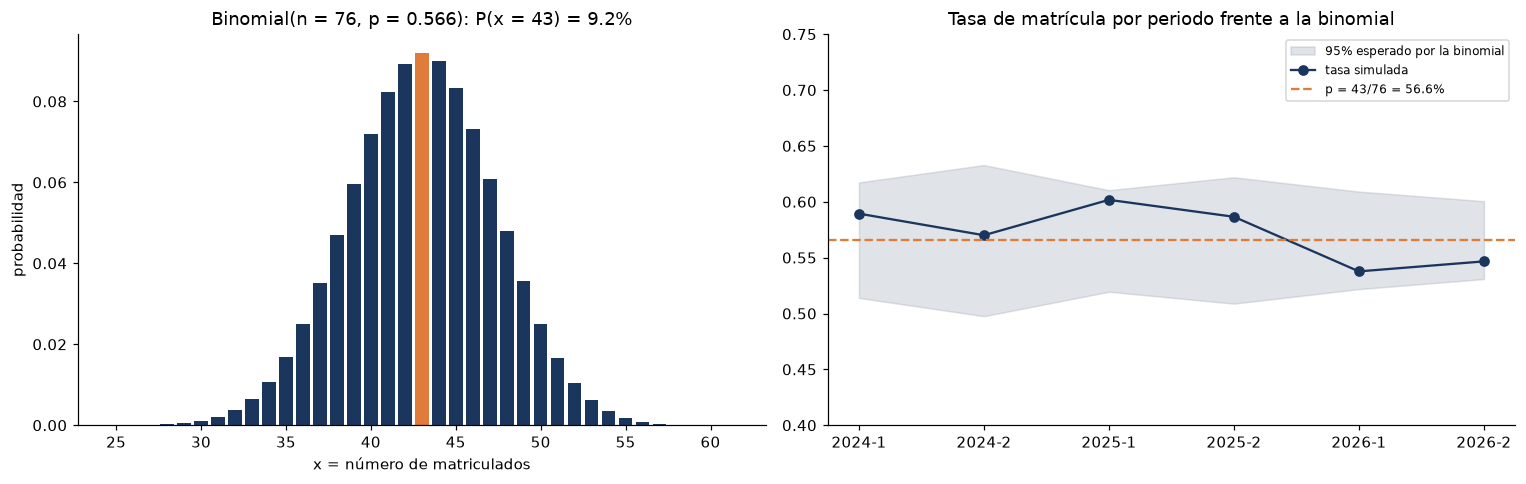

In [12]:
from scipy.stats import binom

from scipy.stats import chi2_contingency

# Muestra de ejemplo (supuesto S-15): conteos agregados por periodo, sin datos personales. [n aspirantes, x matriculados]
MUESTRA = {"2024-1": (22, 16), "2024-2": (9, 4), "2025-1": (8, 6), "2025-2": (9, 3), "2026-1": (28, 14)}
muestra = pd.DataFrame(MUESTRA, index=["n", "x matriculados"]).T
muestra["X no matriculados"] = muestra["n"] - muestra["x matriculados"]
muestra["p = x/n"] = (muestra["x matriculados"] / muestra["n"]).round(3)
N_MUESTRA, X_MUESTRA = int(muestra["n"].sum()), int(muestra["x matriculados"].sum())   # 76 y 43
P = X_MUESTRA / N_MUESTRA
Q = 1 - P
muestra.loc["Total"] = [N_MUESTRA, X_MUESTRA, N_MUESTRA - X_MUESTRA, round(P, 3)]
display(muestra)
chi2, p_valor, gl, _ = chi2_contingency(muestra.iloc[:-1][["x matriculados", "X no matriculados"]].to_numpy())
print(f"Muestra de ejemplo: x = {X_MUESTRA}, X = {N_MUESTRA - X_MUESTRA}, n = {N_MUESTRA} -> p = {P:.1%}, q = {Q:.1%}, "
      f"varianza p·q = {P * Q:.3f}, P(exactamente {X_MUESTRA}) = {binom.pmf(X_MUESTRA, N_MUESTRA, P):.1%}")
print(f"¿La tasa cambia entre periodos? chi-cuadrado = {chi2:.2f} (gl = {gl}), p-valor = {p_valor:.2f}: "
      + ("no hay evidencia de diferencias, se usa una sola p." if p_valor >= 0.05 else "sí hay diferencias entre periodos."))

def resumen_binomial(g: pd.DataFrame) -> dict:
    n, x = len(g), int(g[OBJETIVO].sum())
    return {"n": n, "x matriculados": x, "X no matriculados": n - x, "p = x/n": x / n, "q = X/n": 1 - x / n,
            "varianza p·q": x / n * (1 - x / n), "esperado n·p": n * P, "desviación √(n·p·q)": (n * P * Q) ** 0.5,
            "z": (x - n * P) / (n * P * Q) ** 0.5}

historico = df[df[OBJETIVO].notna()]
tabla_binomial = pd.DataFrame({per: resumen_binomial(g) for per, g in historico.groupby("periodo")}).T
tabla_binomial.loc["Todos (2024-1 a 2026-2)"] = resumen_binomial(historico)
display(tabla_binomial.astype(float).round({"n": 0, "x matriculados": 0, "X no matriculados": 0, "p = x/n": 3, "q = X/n": 3,
                                            "varianza p·q": 3, "esperado n·p": 1, "desviación √(n·p·q)": 1, "z": 2}))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
k = np.arange(25, 62)
ejes[0].bar(k, binom.pmf(k, N_MUESTRA, P), color=[NARANJA if v == X_MUESTRA else AZUL for v in k])
ejes[0].set_title(f"Binomial(n = {N_MUESTRA}, p = {P:.3f}): P(x = {X_MUESTRA}) = {binom.pmf(X_MUESTRA, N_MUESTRA, P):.1%}")
ejes[0].set_xlabel("x = número de matriculados")
ejes[0].set_ylabel("probabilidad")
periodos = tabla_binomial.index[:-1]
n_per = tabla_binomial.loc[periodos, "n"].astype(float)
bajo, alto = binom.ppf(0.025, n_per, P) / n_per, binom.ppf(0.975, n_per, P) / n_per
ejes[1].fill_between(range(len(periodos)), bajo, alto, color=GRIS, alpha=0.3, label="95% esperado por la binomial")
ejes[1].plot(range(len(periodos)), tabla_binomial.loc[periodos, "p = x/n"].astype(float), "o-", color=AZUL, label="tasa simulada")
ejes[1].axhline(P, color=NARANJA, ls="--", label=f"p = 43/76 = {P:.1%}")
ejes[1].set_xticks(range(len(periodos)), periodos)
ejes[1].set_ylim(0.4, 0.75)
ejes[1].set_title("Tasa de matrícula por periodo frente a la binomial")
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de la estadística descriptiva**
- El objetivo está **razonablemente balanceado**: cerca del 57% de los inscritos se matricula (la *p* = 43/76 de la
  muestra de ejemplo) y cada periodo queda dentro de lo que permite la binomial. No hace falta sobremuestreo, pero
  conviene validar por periodo.
- Los puntajes Saber 11 tienen asimetría cercana a 0: son casi simétricos.
- La **distancia al campus** (asimetría ≈ 0,9), los **días entre registro e inscripción** (≈ 2,5), la **edad** (≈ 1,8) y
  los **años desde el Saber 11** (≈ 2,4) tienen cola larga a la derecha. Son candidatas a transformación logarítmica
  o a agruparse en rangos en el Sprint 2.
- Variables como `valor_semestre_bruto` casi no varían dentro de un programa y un año: aportan poco por sí solas,
  pero el **valor neto** (después de la beca) sí varía.

### 3.2 Distribuciones

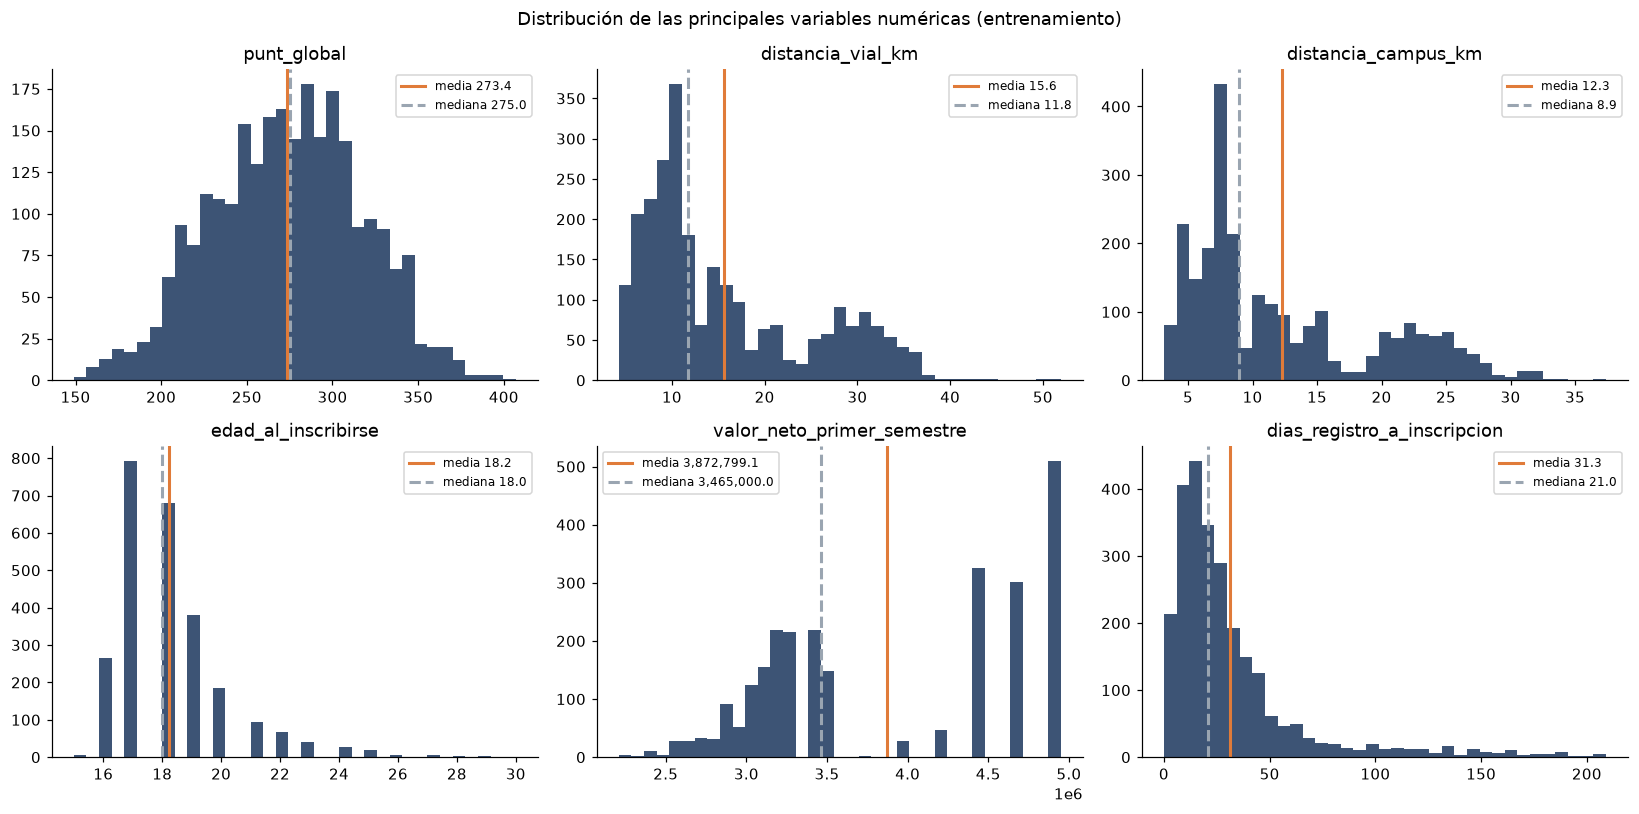

In [13]:
variables = ["punt_global", "distancia_vial_km", "distancia_campus_km", "edad_al_inscribirse",
             "valor_neto_primer_semestre", "dias_registro_a_inscripcion"]
fig, ejes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(ejes.flat, variables):
    x = ent[c].astype(float)
    ax.hist(x, bins=35, color=AZUL, alpha=0.85)
    ax.axvline(x.mean(), color=NARANJA, lw=2, label=f"media {x.mean():,.1f}")
    ax.axvline(x.median(), color=GRIS, lw=2, ls="--", label=f"mediana {x.median():,.1f}")
    ax.set_title(c)
    ax.legend(fontsize=8)
fig.suptitle("Distribución de las principales variables numéricas (entrenamiento)")
plt.tight_layout()
plt.show()

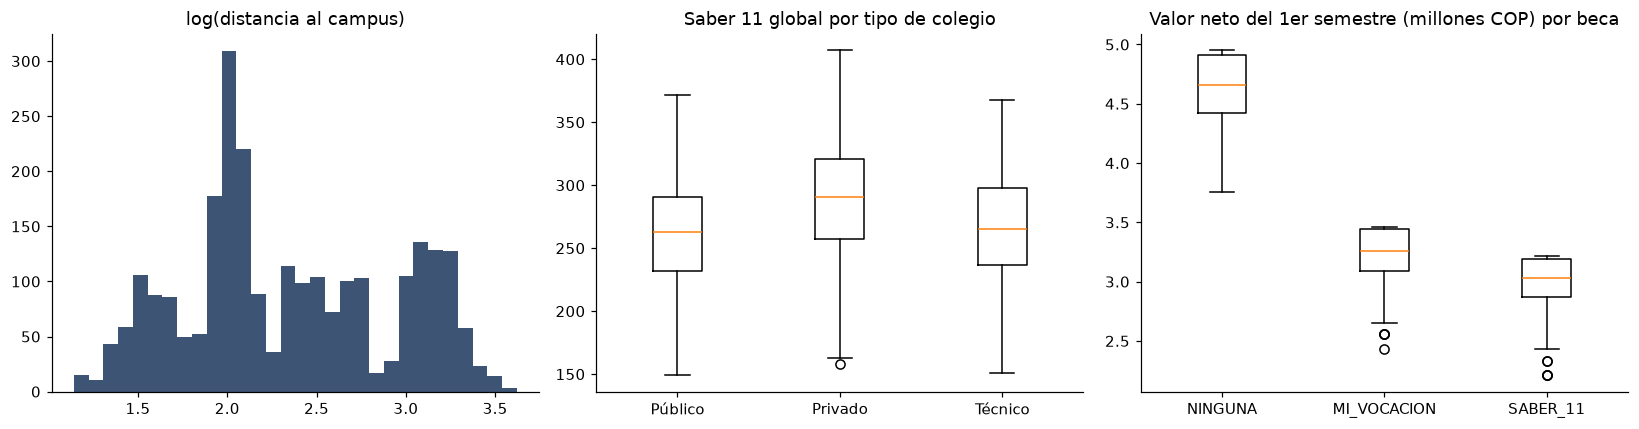

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(np.log(ent["distancia_campus_km"].astype(float)), bins=30, color=AZUL, alpha=0.85)
ejes[0].set_title("log(distancia al campus)")
ejes[1].boxplot([ent.loc[ent["tipo_colegio"] == t, "punt_global"] for t in ["OFICIAL", "PRIVADO", "TECNICO"]])
ejes[1].set_xticks([1, 2, 3], ["Público", "Privado", "Técnico"])
ejes[1].set_title("Saber 11 global por tipo de colegio")
ejes[2].boxplot([ent.loc[ent["beca"] == b, "valor_neto_primer_semestre"] / 1e6 for b in ["NINGUNA", "MI_VOCACION", "SABER_11"]])
ejes[2].set_xticks([1, 2, 3], ["NINGUNA", "MI_VOCACION", "SABER_11"])
ejes[2].set_title("Valor neto del 1er semestre (millones COP) por beca")
plt.tight_layout()
plt.show()

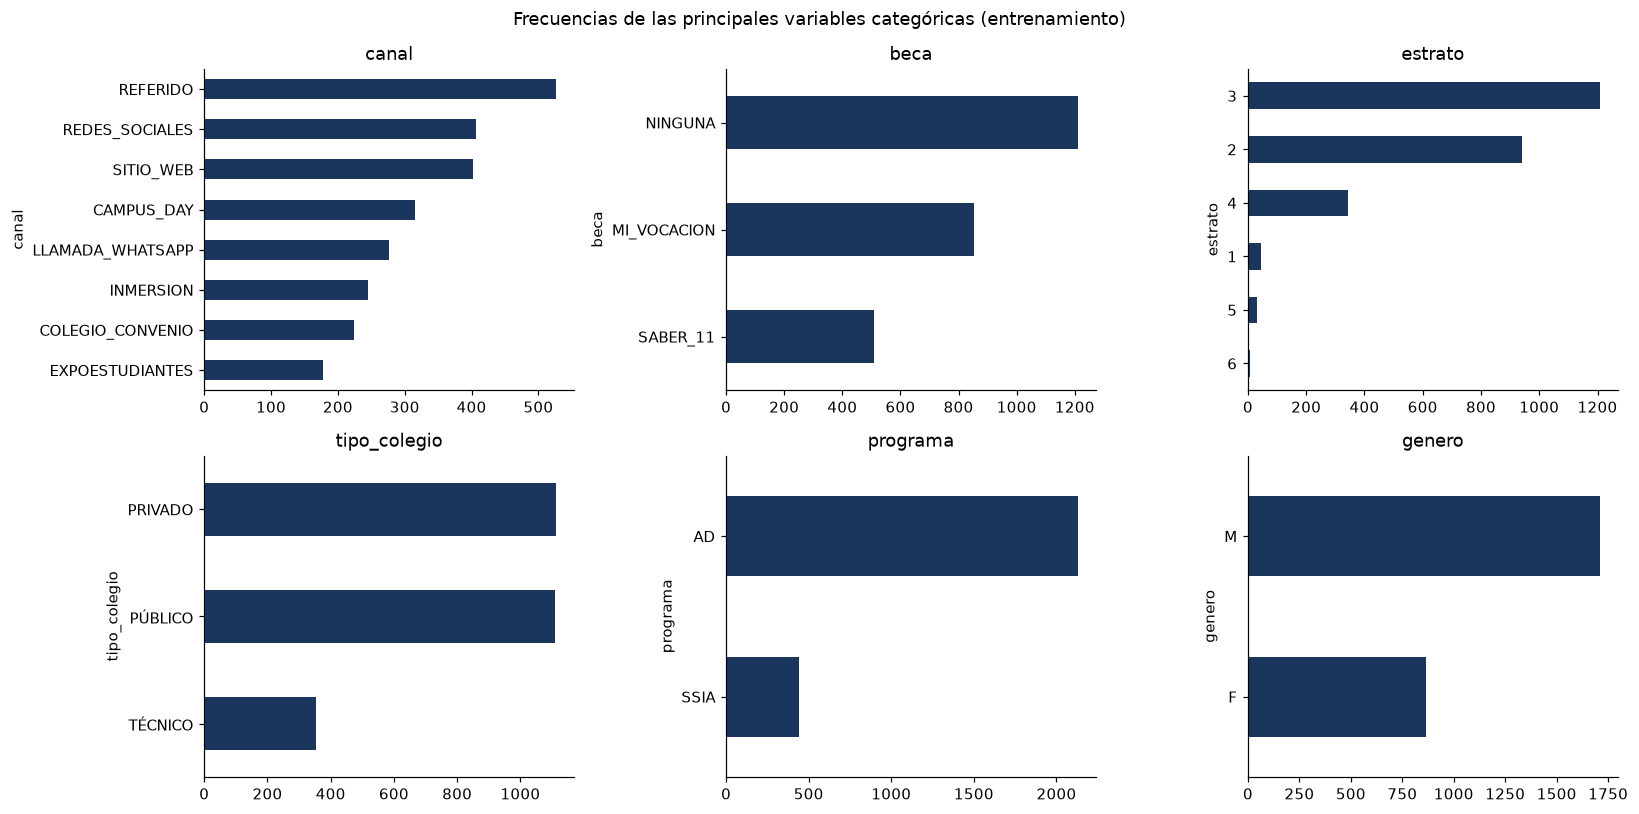

In [15]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(ejes.flat, ["canal", "beca", "estrato", "tipo_colegio", "programa", "genero"]):
    conteo = ent[c].value_counts().sort_values()
    if c == "tipo_colegio":                     # el ICFES dice OFICIAL; para leer se muestra "PÚBLICO"
        conteo = conteo.rename({"OFICIAL": "PÚBLICO", "TECNICO": "TÉCNICO"})
    conteo.plot(kind="barh", ax=ax, color=AZUL)
    ax.set_title(c)
fig.suptitle("Frecuencias de las principales variables categóricas (entrenamiento)")
plt.tight_layout()
plt.show()

In [16]:
def atipicos_iqr(s: pd.Series) -> dict:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"limite_inferior": bajo, "limite_superior": alto, "por_debajo": int((s < bajo).sum()),
            "por_encima": int((s > alto).sum()), "pct_atipicos": round(100 * ((s < bajo) | (s > alto)).mean(), 1)}

atip = pd.DataFrame({c: atipicos_iqr(ent[c].astype(float).dropna()) for c in NUMERICAS}).T
atip[atip["pct_atipicos"] > 0].sort_values("pct_atipicos", ascending=False)

,limite_inferior,limite_superior,por_debajo,por_encima,pct_atipicos
pct_descuento_adicional,0.000,0.000,0.000,345.000,13.400
anios_desde_saber11,-1.500,2.500,0.000,301.000,11.700
dias_registro_a_inscripcion,-25.500,74.500,0.000,212.000,8.200
puntaje_vocacional,1.500,5.500,95.000,0.000,4.400
edad_al_inscribirse,14.000,22.000,0.000,103.000,4.000
distancia_campus_km,-6.845,30.155,0.000,37.000,1.400
estrato,0.500,4.500,0.000,37.000,1.400
colegio_promedio_saber11,199.700,345.300,1.000,25.000,1.000
punt_matematicas,28.000,84.000,12.000,4.000,0.600
punt_ingles,24.000,88.000,1.000,13.000,0.500


**Lectura de las distribuciones**
- El 42% de los inscritos vive a 8 km o menos del campus en línea recta (sobre todo en Suba, Usaquén, Chía y Cota). Por
  vías, el 36% está a 10 km o menos y el 28% a más de 20 km: una cola larga hacia el centro y el sur de Bogotá (hasta
  52 km por vía) y el norte de la Sabana. En escala logarítmica la distribución es más simétrica.
- **Distancia por dirección:** cada inscrito tiene una dirección real (placa de Catastro Bogotá o dirección del DANE en
  Sabana Centro, asignada al azar a una persona ficticia). La distancia se calcula desde esa coordenada, en línea recta
  y por vías (estimada: tramo norte-sur + oriente-occidente, S-44); por eso hay casi un valor distinto por inscrito.
- Los colegios privados tienen puntajes Saber 11 más altos que los públicos. Es el mismo patrón de los datos reales
  del ICFES.
- El valor neto se separa en grupos por beca: la beca baja el valor del primer semestre en 30%.
- Los **atípicos** son valores posibles: personas adultas, residencias lejanas, puntajes muy altos.
  **No se eliminan**

### 3.3 Valores nulos
No todos los vacíos significan lo mismo. Se clasifican antes de tratarlos:

,nulos,pct,nulos_entrenamiento,nulos_campana,tipo,por_que,tratamiento
matriculado,416,13.900,0,416,Censura,Campaña 2027-1: el resultado aún no ocurre,No se imputa: es el conjunto a predecir
colegio_caracter,122,4.100,102,20,Faltante real (ICFES),El ICFES no reporta el carácter de ese colegio,Categoría NO_REPORTA
colegio_bilingue,534,17.900,456,78,Faltante real (ICFES),El ICFES no reporta si el colegio es bilingüe,Categoría NO_REPORTA
puntaje_vocacional,467,15.600,404,63,Estructural,No hubo entrevista con psicología,0 = sin valoración (entrevista_realizada ya lo...
tipo_descuento,2602,87.000,2230,372,Sin clasificar,-,-


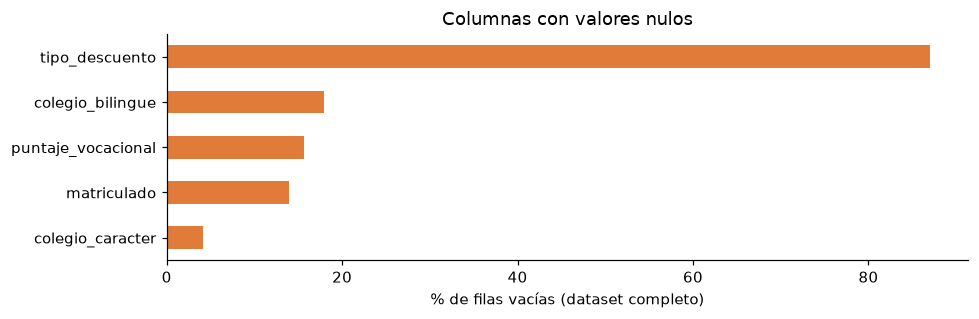

In [17]:
TIPO_NULO = {
    "matriculado": ("Censura", "Campaña 2027-1: el resultado aún no ocurre", "No se imputa: es el conjunto a predecir"),
    "puntaje_vocacional": ("Estructural", "No hubo entrevista con psicología", "0 = sin valoración (entrevista_realizada ya lo indica)"),
    "colegio_caracter": ("Faltante real (ICFES)", "El ICFES no reporta el carácter de ese colegio", "Categoría NO_REPORTA"),
    "colegio_bilingue": ("Faltante real (ICFES)", "El ICFES no reporta si el colegio es bilingüe", "Categoría NO_REPORTA"),
}
nulos = df.isna().sum()
nulos = nulos[nulos > 0]
tabla_nulos = pd.DataFrame({"nulos": nulos, "pct": (100 * nulos / len(df)).round(1),
                            "nulos_entrenamiento": ent[nulos.index].isna().sum(),
                            "nulos_campana": camp[nulos.index].isna().sum()})
tabla_nulos[["tipo", "por_que", "tratamiento"]] = [TIPO_NULO.get(c, ("Sin clasificar", "-", "-")) for c in tabla_nulos.index]
display(tabla_nulos)

fig, ax = plt.subplots(figsize=(9, 3))
tabla_nulos["pct"].sort_values().plot(kind="barh", ax=ax, color=NARANJA)
ax.set_xlabel("% de filas vacías (dataset completo)")
ax.set_title("Columnas con valores nulos")
plt.tight_layout()
plt.show()

In [18]:
# ¿Los vacíos son como se dijo? Se comprueba en vez de suponerlo
print("puntaje_vocacional vacío ⇔ sin entrevista:",
      (df["puntaje_vocacional"].isna() == (df["entrevista_realizada"] == 0)).all())
print("matriculado vacío ⇔ campaña 2027-1:", (df[OBJETIVO].isna() == (df["conjunto"] == "CAMPANA_2027_1")).all())
print("\nColegios sin carácter o sin dato de bilingüismo, por naturaleza (% de inscritos):")
print(df.assign(sin_caracter=df["colegio_caracter"].isna(), sin_bilingue=df["colegio_bilingue"].isna())
        .groupby("colegio_naturaleza")[["sin_caracter", "sin_bilingue"]].mean().mul(100).round(1))

puntaje_vocacional vacío ⇔ sin entrevista: True
matriculado vacío ⇔ campaña 2027-1: True

Colegios sin carácter o sin dato de bilingüismo, por naturaleza (% de inscritos):
                    sin_caracter  sin_bilingue
colegio_naturaleza                            
OFICIAL                    2.200        15.100
PRIVADO                    6.200        21.000


### 3.4 Tratamiento preliminar de nulos
Decisiones (todas reversibles; el dataset de Supabase no se modifica):
1. **Objetivo vacío:** no se imputa. La campaña 2027-1 se separa como conjunto de predicción.
2. **`puntaje_vocacional` vacío:** se reemplaza por **0 = sin valoración**. No se usa la media porque el vacío tiene
   significado (no hubo entrevista) y `entrevista_realizada` ya lo marca.
3. **`colegio_caracter` y `colegio_bilingue` vacíos:** nueva categoría **`NO_REPORTA`**. Imputar la moda inventaría
   un dato que el ICFES no tiene.
4. **`tipo_descuento` vacío:** el inscrito no tiene descuento institucional (la mayoría): categoría **`NINGUNO`**.

En el Sprint 3 este tratamiento quedó dentro del *pipeline* de scikit-learn (`modelado.preparar_X` y
`modelado.construir_pipeline`). Así se aplica igual en entrenamiento, validación y campaña, sin fuga de información.

In [19]:
def tratamiento_preliminar(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["puntaje_vocacional"] = d["puntaje_vocacional"].fillna(0).astype(int)
    for c in ["colegio_caracter", "colegio_bilingue"]:
        d[c] = d[c].fillna("NO_REPORTA")
    d["tipo_descuento"] = d["tipo_descuento"].fillna("NINGUNO")      # sin descuento institucional
    return d

ent_t, camp_t = tratamiento_preliminar(ent), tratamiento_preliminar(camp)
antes = ent[PREDICTORES].isna().sum()
despues = ent_t[PREDICTORES].isna().sum()
print(pd.DataFrame({"antes": antes[antes > 0], "despues": despues[antes > 0]}))
assert despues.sum() == 0 and camp_t[PREDICTORES].isna().sum().sum() == 0
print(f"\nPredictores sin nulos: entrenamiento {ent_t.shape} y campaña {camp_t.shape}. "
      "El objetivo de la campaña sigue vacío a propósito.")

                    antes  despues
puntaje_vocacional    404        0
colegio_caracter      102        0
colegio_bilingue      456        0
tipo_descuento       2230        0

Predictores sin nulos: entrenamiento (2575, 49) y campaña (416, 49). El objetivo de la campaña sigue vacío a propósito.


### 3.5 Primera mirada a la relación con la matrícula
Es un primer acercamiento (correlaciones y tasas por grupo), no el modelo. Sirve para priorizar variables en el
Sprint 2.

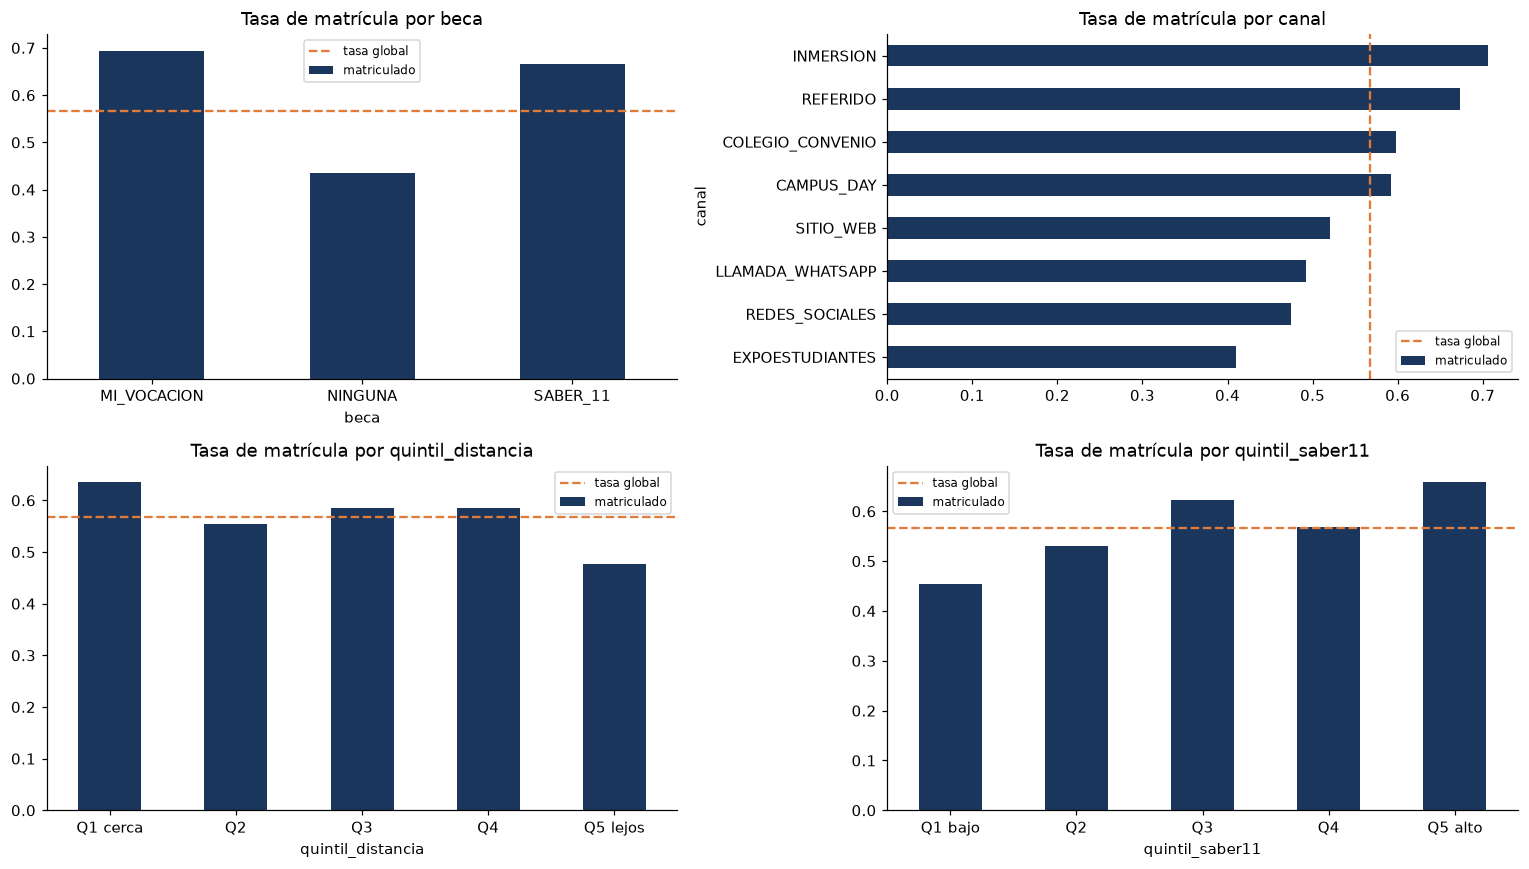

In [20]:
t = ent_t.assign(quintil_distancia=pd.qcut(ent_t["distancia_vial_km"].rank(method="first"), 5,
                                           labels=["Q1 cerca", "Q2", "Q3", "Q4", "Q5 lejos"]),
                quintil_saber11=pd.qcut(ent_t["punt_global"].rank(method="first"), 5,
                                        labels=["Q1 bajo", "Q2", "Q3", "Q4", "Q5 alto"]))
t[OBJETIVO] = t[OBJETIVO].astype(float)
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(ejes.flat, ["beca", "canal", "quintil_distancia", "quintil_saber11"]):
    tasas = t.groupby(c, observed=True)[OBJETIVO].mean()
    if c == "canal":
        tasas = tasas.sort_values()
    tasas.plot(kind="barh" if c == "canal" else "bar", ax=ax, color=AZUL)
    (ax.axvline if c == "canal" else ax.axhline)(t[OBJETIVO].mean(), color=NARANJA, ls="--", label="tasa global")
    ax.set_title(f"Tasa de matrícula por {c}")
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

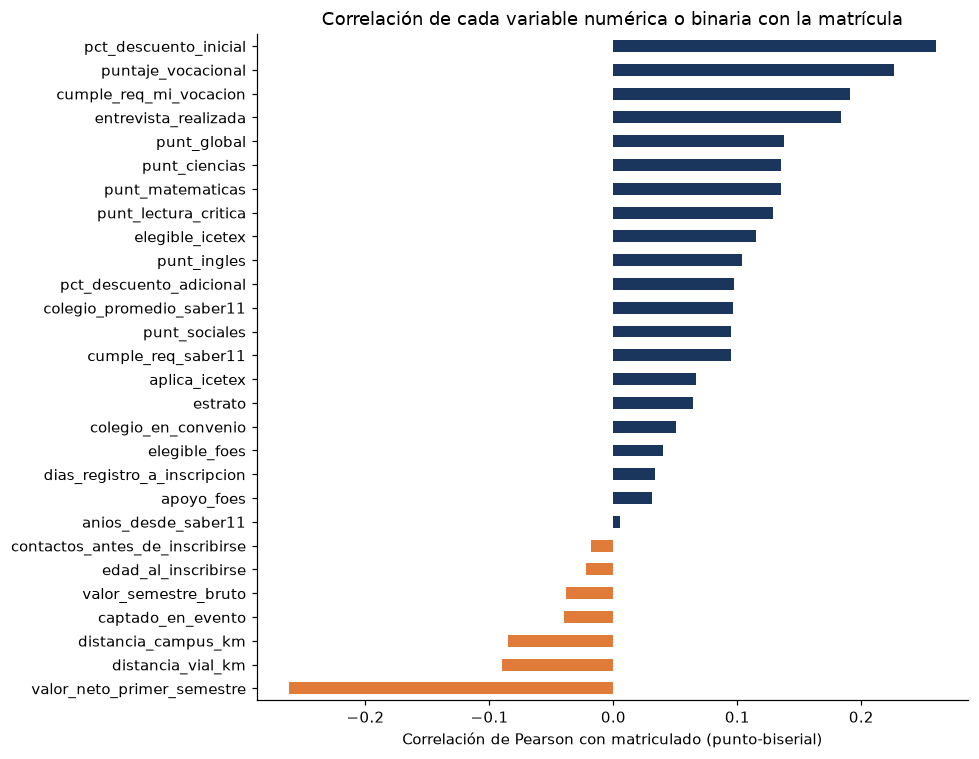

,correlacion_con_matricula
valor_neto_primer_semestre,-0.262
pct_descuento_inicial,0.260
puntaje_vocacional,0.226
cumple_req_mi_vocacion,0.191
entrevista_realizada,0.183
punt_global,0.138
punt_ciencias,0.135
punt_matematicas,0.135
punt_lectura_critica,0.129
elegible_icetex,0.115


In [21]:
corr = (t[NUMERICAS + BINARIAS].astype(float).corrwith(t[OBJETIVO]).dropna()
        .sort_values(key=abs, ascending=False))
fig, ax = plt.subplots(figsize=(9, 7))
corr.sort_values().plot(kind="barh", ax=ax, color=[NARANJA if v < 0 else AZUL for v in corr.sort_values()])
ax.set_title("Correlación de cada variable numérica o binaria con la matrícula")
ax.set_xlabel("Correlación de Pearson con matriculado (punto-biserial)")
plt.tight_layout()
plt.show()
corr.round(3).to_frame("correlacion_con_matricula").head(10)

**Lectura**
- **Beca y valor neto:** con beca se matricula entre el 67% y el 69%; sin beca, cerca del 44%. El descuento baja
  el precio del primer semestre.
- **Descuento institucional e ICETEX:** con descuento (familiar, egresado o personal) se matricula cerca del 69%,
  frente al 55% sin él: quien lo tiene ya conoce la Universidad. Con crédito ICETEX, cerca del 67% frente al 56%.
- **Canal:** inmersión (≈ 70%), referidos, Campus Day y colegio en convenio superan a ExpoEstudiantes, llamadas y
  redes sociales (≈ 41-49%).
- **Distancia (por vías, desde la dirección):** la tasa baja del 63% en el quintil más cercano al 48% en el más lejano.
- **Saber 11:** la tasa sube con el puntaje (45% a 66% por quintil) porque los puntajes altos reciben la Beca Saber 11;
  el modelo separa ese efecto de la "U invertida" (Sprint 4).
- Las correlaciones individuales son **bajas** (la mayor, la del valor neto y el descuento, ronda 0,26), como se espera en un problema
  de comportamiento: ninguna variable sola decide la matrícula.

> Recordatorio: el resultado de matrícula es sintético. Estos patrones reflejan los supuestos documentados del
> generador; con los datos reales de Admisiones el mismo cuaderno se vuelve a ejecutar sin cambios.

## 4. Conclusiones del Sprint 1 y próximos pasos
**Lo que se logró**
1. **Conexión segura:** Python lee Supabase con la API. Las credenciales están en `.env` o en los Secretos de Colab, nunca
   en el código. La clave publicable **solo puede leer** el dataset y la base rechaza cualquier escritura.
2. **Dataset plano:** `dataset_matricula` tiene una fila por inscrito, 49 columnas (3 de control, 1 objetivo y 45
   predictores), la distancia al campus ya calculada, y no tiene datos personales, notas del colegio ni variables con
   fuga.
3. **EDA inicial:** estadística descriptiva, distribuciones, atípicos marcados y nulos clasificados y tratados. Los
   predictores de entrenamiento y de campaña quedan sin vacíos.

**FIN DEL SPRINT 1**

---
**COMIENZA EL SPRINT 2** · entrega del jueves 29 de octubre de 2026 · archivos del sprint en `sprints/sprint_2_caracteristicas/`

# Sprint 2 — Ingeniería de características y regresión logística
**Proyecto:** Modelo Predictivo de Segmentación de Mercado y Propensión a la Matrícula · Unicervantes

**Pedido del docente (Semana 2):** entregar *la misma tabla de datos con columnas nuevas y útiles* (por ejemplo,
"¿Aplica a Beca Mi Vocación? Sí/No" o `segmento_rendimiento_icfes`) y *un primer modelo que sirva de punto de
comparación*. El proyecto predice **solo la matrícula**; el modelo base es una **regresión logística**.

| Sección | Contenido |
|---|---|
| 1 | Datos y partición temporal (entrenamiento, validación, prueba y campaña) |
| 2 | La entrevista de admisión en texto y el modelo NLP del puntaje vocacional |
| 3 | Lo que se aprende SOLO del entrenamiento (sin fuga de datos) |
| 4 | Las 14 columnas nuevas |
| 5 | Segmentación de mercado con k-means |
| 6 | Relación de las columnas nuevas con la matrícula |
| 7 | Regresión logística y su error |

## 1. Datos y partición temporal
Los datos se dividen por **tiempo**, no al azar: se aprende con el pasado y se evalúa con el futuro, como pasará en la
realidad. La campaña 2027-1 no tiene resultado (se predice); su resultado real está sellado hasta el Sprint 5.

| Conjunto | Periodos | Para qué |
|---|---|---|
| ENTRENAMIENTO | 2024-1 a 2025-2 | Aprender escalas, k-means y modelos |
| VALIDACION | 2026-1 | Elegir hiperparámetros (Sprint 3) |
| PRUEBA | 2026-2 | Medir el error final, una sola vez |
| CAMPANA | 2027-1 | Lo que el modelo predice |

In [22]:
import caracteristicas as ca
import flujo
import modelado as mo

# Lee las tablas planas por la API de Supabase (solo lectura): dataset_matricula y las respuestas de la entrevista
# (dataset_entrevista). Sin clave de Supabase usa la copia de esas tablas: en el computador, la del repositorio; en
# Colab, la que está en GitHub (no hay que subir nada). Después construye las columnas del Sprint 2 (con el puntaje NLP).
f = flujo.cargar_y_construir("auto")
d, ref, cfg = f["inscritos"], f["referencias"], ca.configuracion()
print("Origen de los datos:", f["origen"])
print(f"Inscritos: {len(d):,} · con entrevista: {int(d['entrevista_realizada'].sum()):,}")
print(d["particion"].value_counts().to_string())

Origen de los datos: Supabase (API de solo lectura)
Inscritos: 2,991 · con entrevista: 2,524
particion
ENTRENAMIENTO    1310
PRUEBA            761
VALIDACION        504
CAMPANA           416


## 2. La entrevista de admisión en texto y el modelo NLP
La entrevista de admisión es **cualitativa**: el aspirante responde con sus palabras. Se usan tres secciones del
formulario de Unicervantes, con 13 preguntas abiertas:

| Sección | Preguntas |
|---|---|
| Interés por el programa académico | Por qué la carrera, defina el programa, qué le gusta, cómo se ve como profesional, otra carrera |
| Historia de vida | Sobre usted, ocupación del hogar, trabajo y financiación, cualidades, aspectos por mejorar, colegio, tiempo libre |
| Interés por la universidad | ¿Por qué quiere estudiar en Unicervantes? |

El entrevistador da un **puntaje vocacional de 1 a 5** (está en `dataset_matricula`). Un **modelo NLP** lee las
respuestas y aprende qué palabras acompañan a cada puntaje:

1. **Preprocesamiento:** minúsculas, sin tildes, sin palabras vacías ("de", "la", "que"…), pero conservando las que
   cambian el sentido ("no", "todavía", "ya"). Se forman palabras y pares de palabras dentro de cada frase.
2. **TF-IDF:** cada término pesa más si aparece mucho en esa entrevista y poco en las demás. Un TF-IDF por sección.
3. **Regresión Ridge:** aprende el peso de cada término para estimar el puntaje del entrevistador. Ridge castiga los
   pesos grandes (α elegido con validación cruzada **dentro** del entrenamiento).

El resultado, `puntaje_vocacional_nlp` (1 a 5), es la vocación según las palabras del propio aspirante. No copia al
entrevistador: las palabras también muestran lo que él no alcanza a ver, y por eso pueden ayudar a predecir la
matrícula (Sprint 3).

- **Sin fuga de datos:** el NLP se ajusta solo con el entrenamiento. Las entrevistas del entrenamiento reciben una
  predicción **fuera de pliegue** (validación cruzada de 5 pliegues): ninguna se puntúa con un modelo que ya la vio.

> No hay respuestas reales de entrevistas en datos abiertos: se simulan con un banco de frases en español (supuestos
> S-48 y S-49, `src/textos_entrevista.py`).

In [23]:
import caracteristicas as ca
import nlp_vocacion as nv

print(f"Inscritos con entrevista: {int(d['entrevista_realizada'].sum()):,} de {len(d):,} (13 respuestas cada uno)")
preguntas = pd.DataFrame(cfg["generador"]["entrevista_texto"]["preguntas"])
display(preguntas.rename(columns={"id": "pregunta", "seccion": "sección", "texto": "pregunta del formulario"}))
textos = f["entrevista"]                     # las respuestas por sección: la entrada del NLP
ejemplo = textos[textos["texto_interes_programa"].notna()].iloc[0]
for col, nombre in nv.SECCIONES.items():
    print(f"\n{nombre}:\n  {ejemplo[col]}")
print("\nCómo lo ve el modelo (primera sección, primeros 20 términos):", nv.terminos(ejemplo["texto_interes_programa"])[:20])

Inscritos con entrevista: 2,524 de 2,991 (13 respuestas cada uno)


,pregunta,sección,pregunta del formulario
0,1,INTERES_PROGRAMA,¿Por qué quiere estudiar esta carrera profesio...
1,2,INTERES_PROGRAMA,Por favor defina su programa elegido
2,3,INTERES_PROGRAMA,¿Qué es lo que más le gusta de la carrera?
3,4,INTERES_PROGRAMA,¿Cómo se ve en un futuro como profesional?
4,5,INTERES_PROGRAMA,"Si tuviera que elegir otra carrera, ¿cuál serí..."
5,6,HISTORIA_VIDA,Cuéntenos sobre usted
6,7,HISTORIA_VIDA,Ocupación de las personas con quien vive
7,8,HISTORIA_VIDA,¿Trabaja? ¿Cómo ha planeado financiar sus estu...
8,9,HISTORIA_VIDA,¿Cuáles considera que son sus cualidades y/o h...
9,10,HISTORIA_VIDA,¿Qué aspectos considera que debe mejorar en us...



Interés por el programa académico:
  Me interesa la tecnología y quiero aprender más sobre el aprendizaje automático. Es una ingeniería que mezcla las matemáticas con la programación. Que puedo aplicar la inteligencia de negocios en salud, educación o medio ambiente y ayudar a la gente. La verdad, con un buen trabajo y ayudando a mi familia. Mmm, cualquiera, la verdad no estoy seguro.

Historia de vida:
  Me considero constante: cuando algo me interesa, investigo hasta entenderlo. Vivo con mi mamá, que trabaja en un almacén, y con mi abuela, que es pensionada. Mmm, no trabajo; me dedico a estudiar. Mis papás me van a ayudar con la matrícula. Tengo la Beca Saber 11 por mi puntaje, y eso me ayuda mucho. Considero que mis cualidades son la perseverancia, el pensamiento lógico y la creatividad para resolver problemas. Debo mejorar el manejo del estrés, la timidez y el orden en mis cosas. Mi rendimiento fue bueno. Me gustaban las matemáticas; me costaba química. En mi tiempo libre me gusta

### Qué aprendió el modelo NLP
Las palabras con peso positivo suben el puntaje vocacional; las de peso negativo lo bajan. Se mide en la validación
(2026-1), que el NLP nunca vio: error absoluto medio (MAE) frente al puntaje del entrevistador, comparado con predecir
siempre el promedio, y la correlación de Spearman (orden).

Entrevistas de entrenamiento: 1,097 · términos: 1,821 · α de Ridge: 10.0


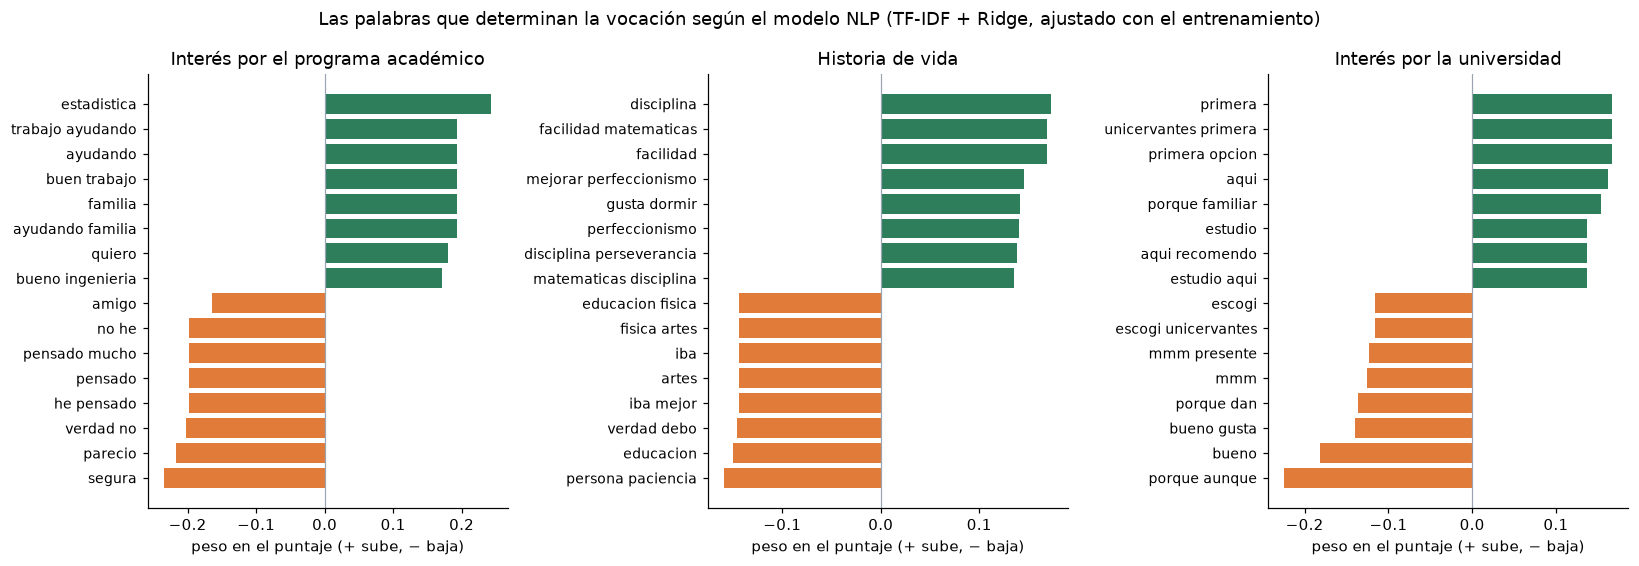

,n,mae,mae_promedio,spearman,pct_a_un_punto,AUC del NLP solo (matrícula)
ENTRENAMIENTO,"1,097.000",0.654,0.909,0.657,77.940,0.651
VALIDACION,429.000,0.653,0.931,0.682,77.622,0.619


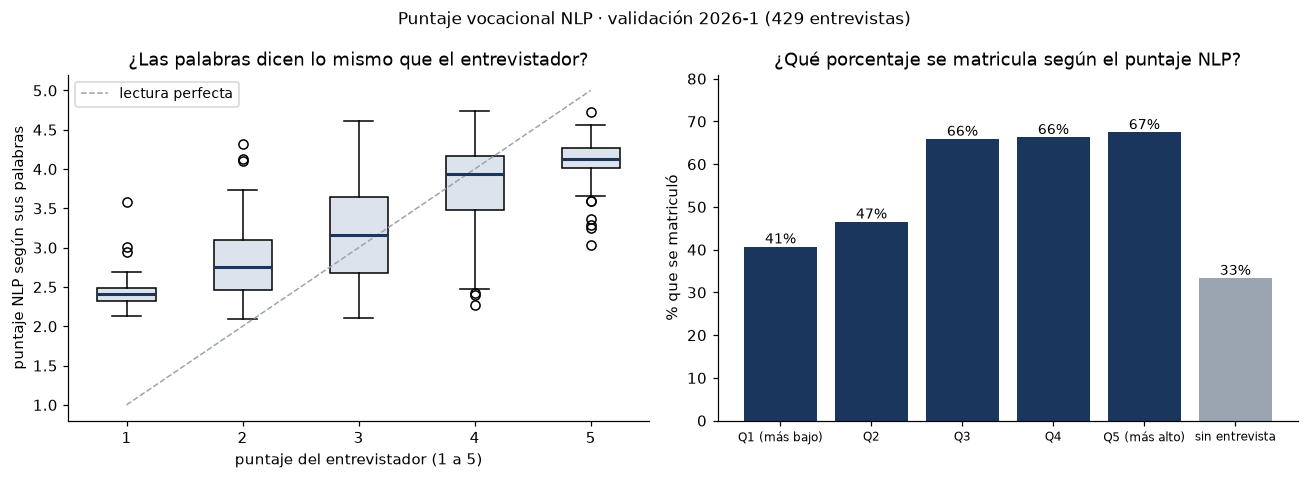

En la validación el NLP se equivoca 0.65 puntos en promedio frente al entrevistador (predecir siempre el promedio: 0.93).


In [24]:
import graficas_sprint2 as gr
from sklearn.metrics import roc_auc_score


def ver(fig):
    """Muestra la figura en su lugar (antes de las tablas que siguen) y la cierra."""
    display(fig)
    plt.close(fig)


nlp = ref["nlp"]
print(f"Entrevistas de entrenamiento: {nlp['n_entrevistas']:,} · términos: {nlp['n_terminos']:,} · α de Ridge: {nlp['alpha']}")
ver(gr.palabras_nlp(nv.palabras_clave(nlp)))
filas = {}
for conj in ["ENTRENAMIENTO", "VALIDACION"]:
    x = flujo.conjunto(d, conj).dropna(subset=["puntaje_vocacional_nlp"])
    filas[conj] = nv.metricas(x["puntaje_vocacional"], x["puntaje_vocacional_nlp"], nlp["media_entrenamiento"]) | {
        "AUC del NLP solo (matrícula)": roc_auc_score(x["matriculado"].astype(int), x["puntaje_vocacional_nlp"])}
display(pd.DataFrame(filas).T.round(3))
ver(gr.puntaje_nlp(d, "VALIDACION"))
v = filas["VALIDACION"]
print(f"En la validación el NLP se equivoca {v['mae']:.2f} puntos en promedio frente al entrevistador "
      f"(predecir siempre el promedio: {v['mae_promedio']:.2f}).")

## 3. Lo que se aprende solo del entrenamiento
Si las escalas o los grupos se calcularan con todos los datos, la validación y la prueba "verían" información del
futuro (fuga de datos) y el error saldría engañosamente bajo. Por eso `ajustar_referencias` usa **solo** el
entrenamiento: la media y la desviación del Saber 11 (para su término cuadrático), los grupos de k-means y el modelo NLP.

In [25]:
print("Estandarización (media y desviación del entrenamiento):")
display(pd.DataFrame(ref["estandarizacion"], index=["media", "desviación"]).round(3))

Estandarización (media y desviación del entrenamiento):


,punt_global
media,273.138
desviación,42.662


## 4. Las columnas nuevas
Cada columna responde una pregunta de negocio. Las que dependen de una regla (Sí/No de becas, bandas del ICFES,
valor neto) se calculan igual para todos; las que dependen de datos (k-means y el puntaje NLP) usan lo aprendido en
el entrenamiento.

In [26]:
print(f"Columnas nuevas: {len(ca.NUEVAS)}")
display(pd.DataFrame({"columna": list(ca.DICCIONARIO), "qué es": list(ca.DICCIONARIO.values())}))
muestra = d[["inscripcion_id", "periodo", "punt_global", "aplica_beca_saber11", "aplica_beca_mi_vocacion",
             "puntaje_vocacional", "puntaje_vocacional_nlp", "segmento_rendimiento_icfes",
             "valor_neto_primer_semestre", "ahorro_beca_primer_semestre", "zona_distancia", "segmento_mercado"]]
display(muestra.head(8))
print("¿Aplica a Mi Vocación?", d["aplica_beca_mi_vocacion"].value_counts().to_dict(),
      "· ¿Aplica a Saber 11?", d["aplica_beca_saber11"].value_counts().to_dict())
print("Nulos en las columnas nuevas:", int(d[ca.NUEVAS].drop(columns="puntaje_vocacional_nlp").isna().sum().sum()),
      "· puntaje NLP vacío solo sin entrevista:", int(d["puntaje_vocacional_nlp"].isna().sum()))

Columnas nuevas: 14


,columna,qué es
0,particion,Conjunto temporal: ENTRENAMIENTO (2024-1 a 202...
1,aplica_beca_saber11,Sí/No: puntaje global Saber 11 ≥ 310 (requisit...
2,aplica_beca_mi_vocacion,Sí/No: presentó entrevista y su puntaje vocaci...
3,puntaje_vocacional_nlp,Puntaje vocacional de 1 a 5 que el modelo NLP ...
4,segmento_rendimiento_icfes,"BAJO (< 250), MEDIO (250-309), ALTO (310-349: ..."
5,ahorro_beca_primer_semestre,Cuánto le ahorran la beca y el descuento en el...
6,log_distancia,Logaritmo natural de la distancia por vías des...
7,zona_distancia,Distancia por vías desde la dirección: CERCA (...
8,rezago_saber11,INMEDIATO (presentó el Saber 11 el año anterio...
9,canal_agrupado,"EVENTO (Expo, Campus Day), RELACIONAL (referid..."


,inscripcion_id,periodo,punt_global,aplica_beca_saber11,aplica_beca_mi_vocacion,puntaje_vocacional,puntaje_vocacional_nlp,segmento_rendimiento_icfes,valor_neto_primer_semestre,ahorro_beca_primer_semestre,zona_distancia,segmento_mercado
0,1,2026-1,325,Sí,Sí,4,3.344,ALTO,3194100,1719900,CERCA,"S1: Colegio privado, estrato más alto"
1,2,2025-1,298,No,No,2,2.348,MEDIO,4658000,0,MEDIA,"S1: Colegio privado, estrato más alto"
2,3,2025-2,229,No,Sí,3,2.482,BAJO,4658000,0,MEDIA,"S4: Aspirantes mayores, puntaje ICFES bajo"
3,4,2026-2,256,No,No,<NA>,NaN,MEDIO,4914000,0,CERCA,"S2: Colegio público, viven cerca del campus"
4,5,2026-2,341,Sí,Sí,4,3.760,ALTO,2702700,2211300,CERCA,"S1: Colegio privado, estrato más alto"
5,6,2026-2,235,No,No,<NA>,NaN,BAJO,4455000,495000,MEDIA,"S2: Colegio público, viven cerca del campus"
6,7,2026-2,261,No,No,<NA>,NaN,MEDIO,4914000,0,LEJOS,"S3: Viven lejos del campus, estrato más bajo"
7,8,2025-1,274,No,Sí,5,4.333,MEDIO,2794800,1863200,CERCA,"S1: Colegio privado, estrato más alto"


¿Aplica a Mi Vocación? {'Sí': 2067, 'No': 924} · ¿Aplica a Saber 11? {'No': 2360, 'Sí': 631}
Nulos en las columnas nuevas: 0 · puntaje NLP vacío solo sin entrevista: 467


## 5. Segmentación de mercado con k-means
k-means agrupa a los aspirantes por parecido en su perfil (estrato, distancia, ICFES, edad y tipo de colegio). No se
usan la media ICFES del colegio (Admisiones no suele tener ese dato) ni las notas del colegio (dejaron de ser variables
del análisis). Antes se **estandarizan** las variables (restar la media y dividir por la desviación), para que ninguna pese
más solo por estar en otra escala. El número de grupos k se elige con la **silueta**: qué tan cerca está cada aspirante
de su grupo frente al grupo vecino (de −1 a 1; más alto es mejor).

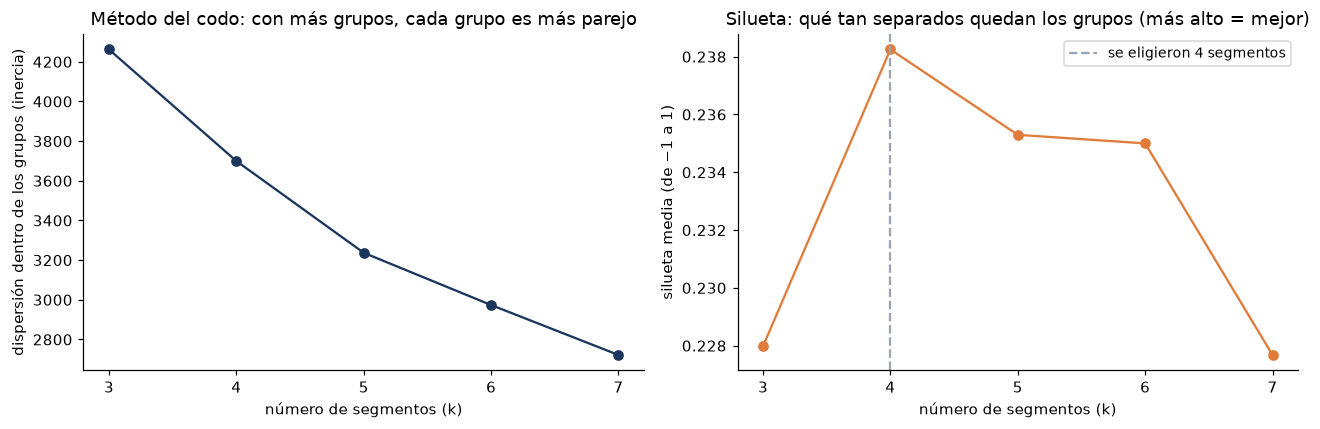

Mapa de los segmentos: las 6 variables proyectadas en 2 dimensiones (componentes principales).


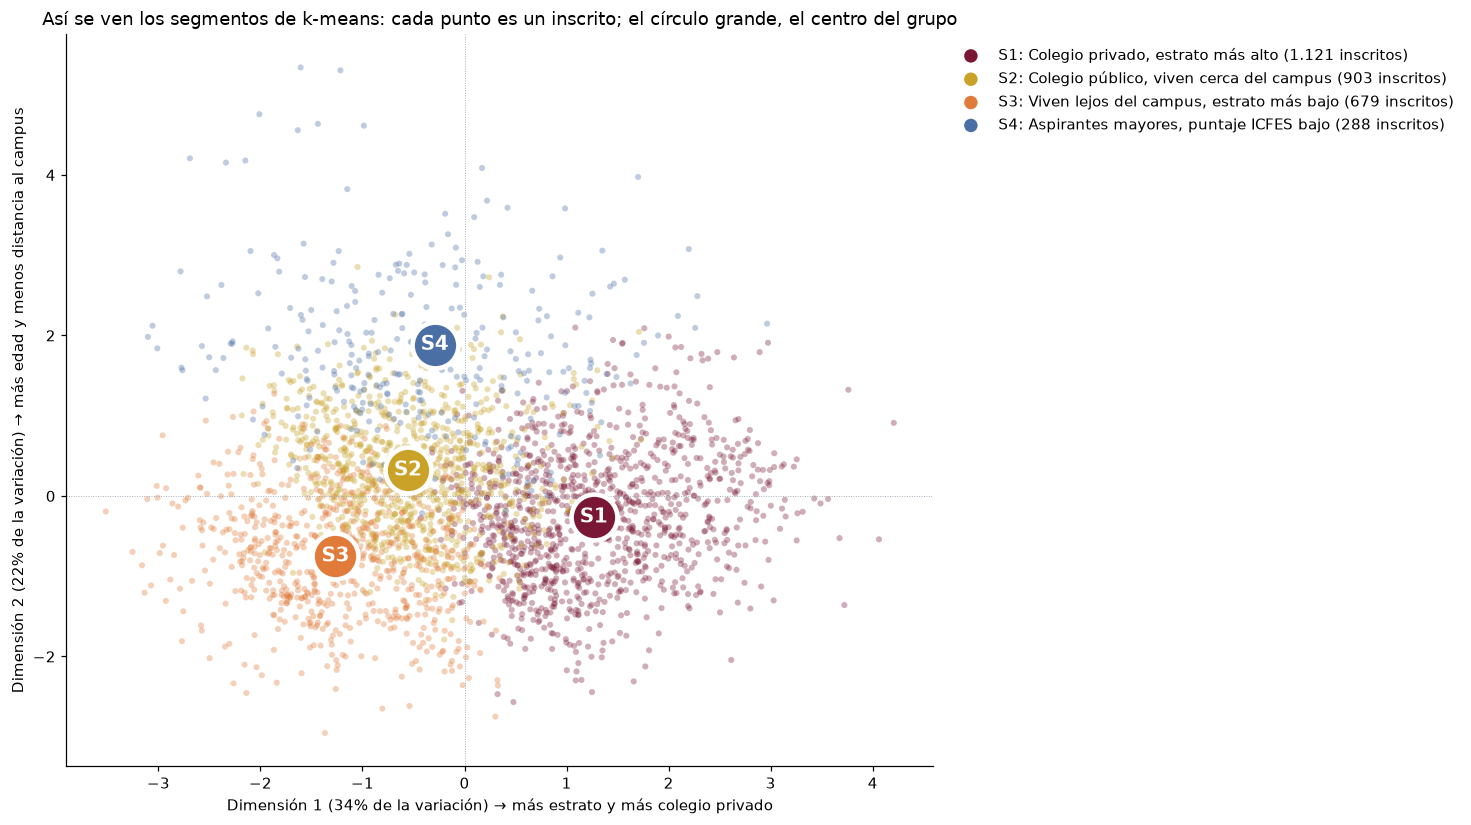

Cada segmento se nombra por los 2 rasgos en que más se aleja del promedio de los inscritos.


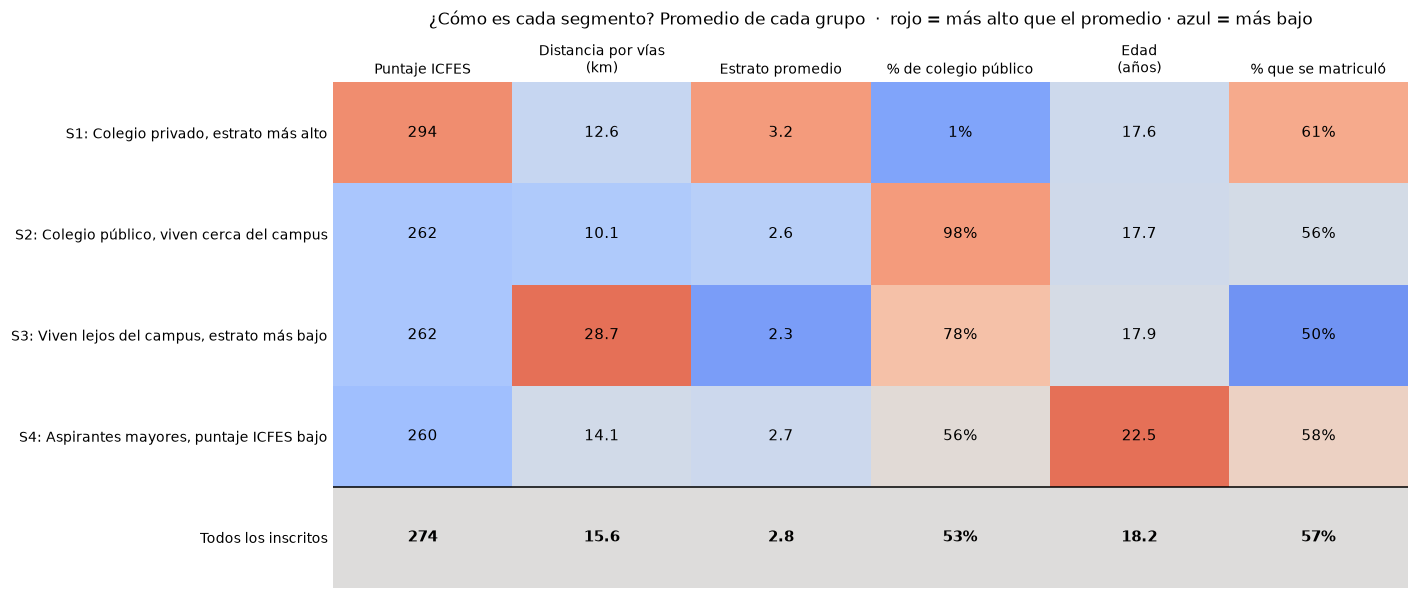

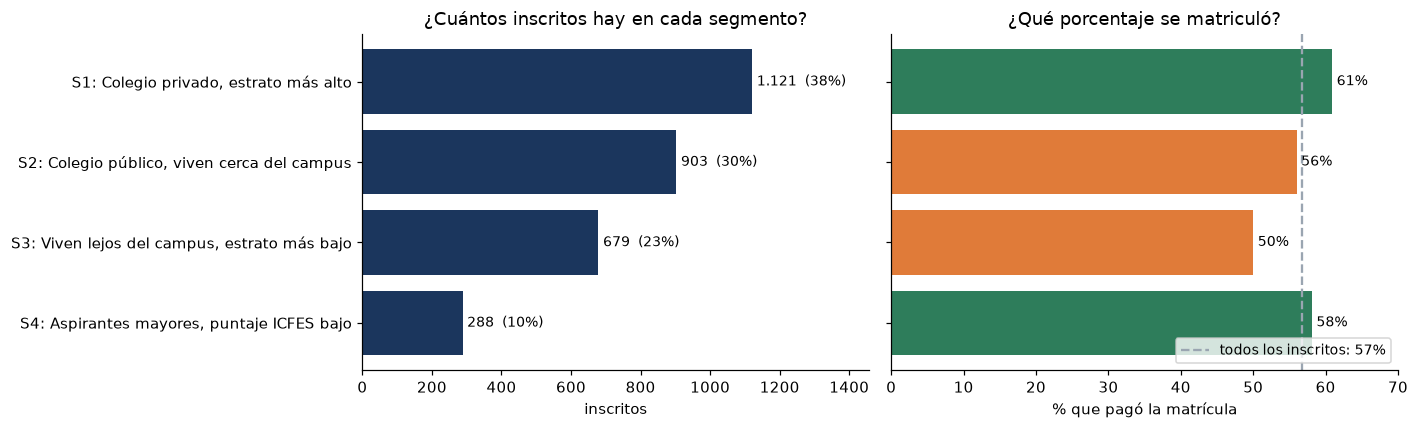

Tabla de segmentos (promedios reales de cada grupo):


,Inscritos,% del total,% que se matriculó,Puntaje ICFES,Distancia por vías (km),Estrato promedio,% de colegio público,Edad (años)
Segmento de mercado,,,,,,,,
"S1: Colegio privado, estrato más alto",1121,37.500,60.900,294.000,12.600,3.200,1.000,17.600
"S2: Colegio público, viven cerca del campus",903,30.200,56.000,262.000,10.100,2.600,98.000,17.700
"S3: Viven lejos del campus, estrato más bajo",679,22.700,50.000,262.000,28.700,2.300,78.000,17.900
"S4: Aspirantes mayores, puntaje ICFES bajo",288,9.600,58.100,260.000,14.100,2.700,56.000,22.500
Todos los inscritos,2991,100.000,56.700,274.000,15.600,2.800,53.000,18.200


In [27]:
ver(gr.eleccion_k(ref))
print("Mapa de los segmentos: las 6 variables proyectadas en 2 dimensiones (componentes principales).")
ver(gr.mapa_segmentos(d, ref))
print("Cada segmento se nombra por los 2 rasgos en que más se aleja del promedio de los inscritos.")
ver(gr.perfil_segmentos(d))
ver(gr.tamano_y_matricula(d))
print("Tabla de segmentos (promedios reales de cada grupo):")
display(ca.tabla_segmentos(d))

**Cómo leer el mapa.** k-means usa 5 variables a la vez, así que no se puede dibujar directamente. El mapa las resume en
2 dimensiones (componentes principales): cada punto es un inscrito, el color es el segmento que le asignó k-means y el
círculo grande es el centro del grupo. Los grupos se tocan en los bordes: por eso la silueta es baja.

**Cómo leer los nombres.** Cada segmento se nombra con los **2 rasgos en que más se diferencia del promedio**
de todos los inscritos. Los nombres son **relativos**: "viven cerca del campus" quiere decir más cerca que el promedio
(15,6 km por vías), no a menos de cierta distancia; "colegio público" quiere decir que casi todos vienen de colegios
oficiales (públicos). La tabla muestra los valores reales para comprobarlo.

| Segmento | En palabras sencillas |
|---|---|
| S1: Colegio privado, estrato más alto | El grupo más grande: colegios privados, estratos más altos y el mejor ICFES (muchos aplican a la beca Saber 11); el que más se matricula |
| S2: Colegio público, viven cerca del campus | Egresados de colegios públicos que viven relativamente cerca (unos 10 km por vías) |
| S3: Viven lejos del campus, estrato más bajo | Viven a unos 29 km por vías y son de estratos 1 y 2; el que menos se matricula |
| S4: Aspirantes mayores, puntaje ICFES bajo | Unos 22 años en promedio: no vienen directo del colegio |

**Qué tan buenos son los grupos.** La silueta es baja (cerca de 0,24): los aspirantes no forman grupos muy separados,
algo común en datos de personas. Aun así, los segmentos tienen perfiles con sentido de negocio y tasas de matrícula
distintas (del 49% al 61%), por eso sirven para orientar la estrategia de captación (Sprint 5).

## 6. Relación de las columnas nuevas con la matrícula (entrenamiento)

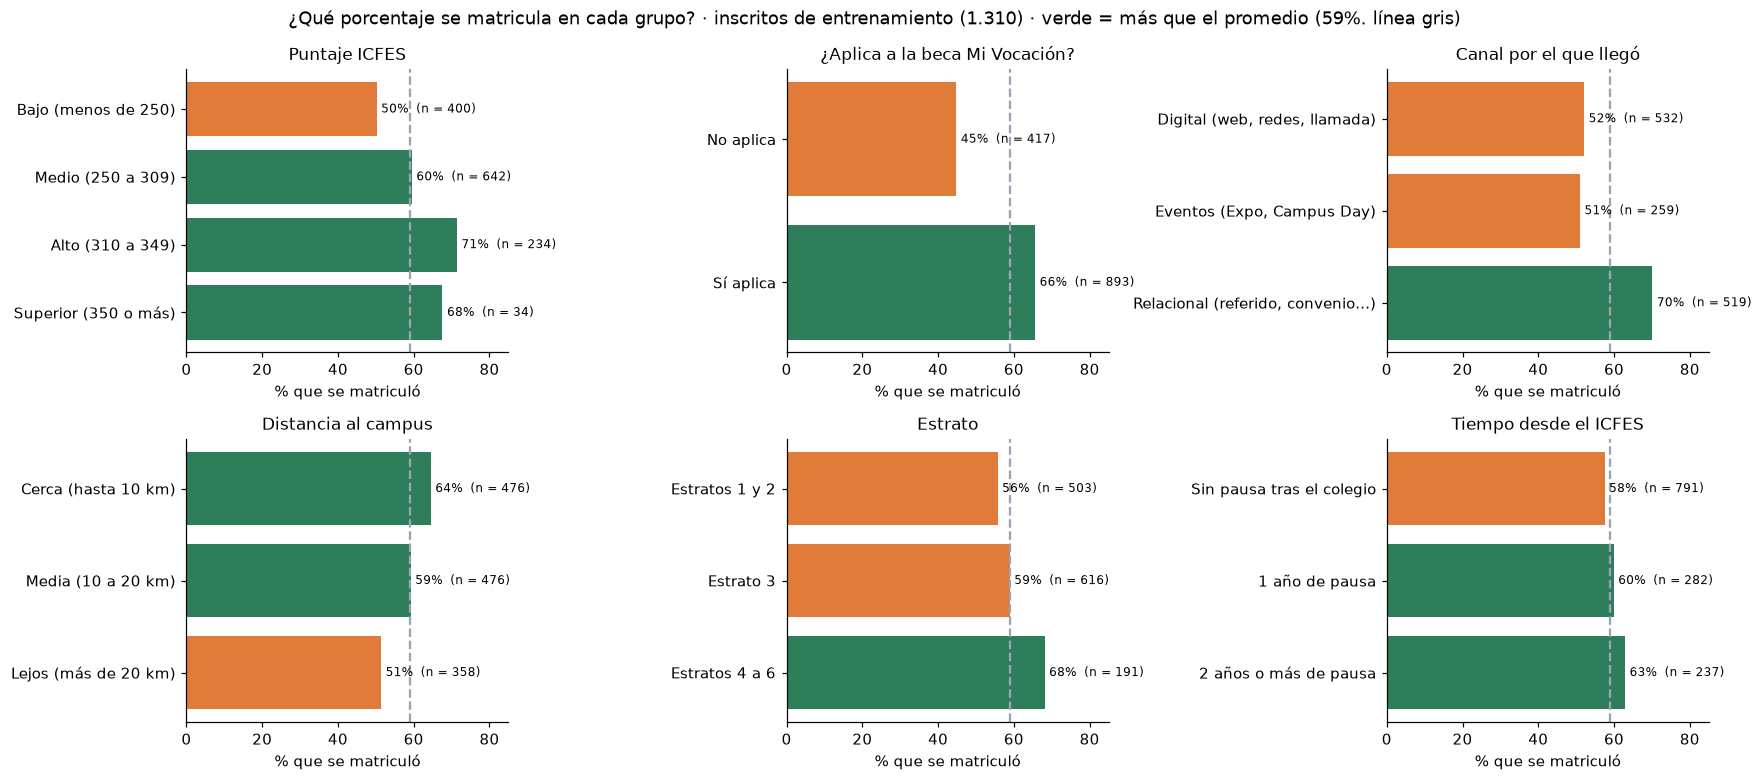

,Característica,Grupo,Inscritos,% que se matriculó
0,Puntaje ICFES,Bajo (menos de 250),400,50.200
1,Puntaje ICFES,Medio (250 a 309),642,59.500
2,Puntaje ICFES,Alto (310 a 349),234,71.400
3,Puntaje ICFES,Superior (350 o más),34,67.600
4,¿Aplica a la beca Mi Vocación?,No aplica,417,44.800
5,¿Aplica a la beca Mi Vocación?,Sí aplica,893,65.600
6,Canal por el que llegó,"Digital (web, redes, llamada)",532,52.100
7,Canal por el que llegó,"Eventos (Expo, Campus Day)",259,51.000
8,Canal por el que llegó,"Relacional (referido, convenio…)",519,70.100
9,Distancia al campus,Cerca (hasta 10 km),476,64.500


,correlación con la matrícula
puntaje_vocacional,0.154
Puntaje vocacional de 1 a 5 que el modelo NLP lee en las palabras del aspirante (respuestas de la entrevista; TF-IDF + Ridge ajustado con el entrenamiento); vacío si no hubo entrevista,0.248
valor_neto_primer_semestre,-0.280
Logaritmo natural de la distancia por vías desde la dirección hasta el campus (S-44; reduce la cola larga),-0.096


In [28]:
ent = flujo.conjunto(d, "ENTRENAMIENTO")
columnas = ["segmento_rendimiento_icfes", "aplica_beca_mi_vocacion", "canal_agrupado", "zona_distancia", "estrato_grupo",
            "rezago_saber11"]
ver(gr.matricula_por_grupo(ent, columnas))
display(gr.tabla_matricula_por_grupo(ent, columnas))
correl = ent[["puntaje_vocacional", "puntaje_vocacional_nlp", "valor_neto_primer_semestre", "log_distancia"]].corrwith(
    ent["matriculado"].astype(float))
display(correl.rename(ca.DICCIONARIO).round(3).rename("correlación con la matrícula").to_frame())

**Lectura.**
- El segmento ICFES ALTO (310-349) se matricula más que el SUPERIOR (≥ 350): los puntajes muy altos tienen más
  opciones puesto a que las universidades los buscan. Es la "U invertida" que el modelo deberá captar.
- Quien aplica a Mi Vocación se matricula más: la beca baja el precio.
- Los canales relacionales (referido, inmersión, convenio) convierten más que los eventos y lo digital.
- La matrícula baja con la distancia al campus (por vías, desde la dirección de cada inscrito).
- Quien presentó la entrevista se matricula más que quien no la presentó. Entre los entrevistados, el puntaje NLP se
  relaciona con la matrícula más que el puntaje del entrevistador: las palabras muestran algo más que su calificación.

## 7. Regresión logística: el primer modelo
La regresión logística estima la **probabilidad** de que un inscrito se matricule a partir de todas sus variables:

`log(p / (1 − p)) = β₀ + β₁x₁ + … + βₖxₖ`

Cada β dice cuánto sube o baja la probabilidad cuando la variable cambia. Las variables numéricas se estandarizan y las
categóricas se codifican con *one-hot* (una columna 0/1 por categoría), dentro del mismo modelo.

- Se entrena solo con el **entrenamiento** (2024-1 a 2025-2) y **sin ajustar hiperparámetros**: C = 1, fijado antes de
  ver resultados (configuración del proyecto, `modelado.sprint2_logistica`). El ajuste se hace en el Sprint 3.
- Se predice "se matricula" si la probabilidad es ≥ 50%. El **error %** es el porcentaje de inscritos mal clasificados.
- El **AUC** mide qué tan bien ordena a los inscritos: 0,5 es azar y 1 es perfecto.
- La entrevista entra con el **puntaje del entrevistador** (0 si no hubo entrevista). El puntaje NLP se agrega en el
  Sprint 3, para medir cuánto mejora el modelo.
- Es el **modelo base** del proyecto: el Sprint 3 lo compara con modelos más avanzados.

Los 10 coeficientes más grandes (variables estandarizadas; positivo = sube la probabilidad):


,β
canal_INMERSION,0.622
canal_REFERIDO,0.557
canal_REDES_SOCIALES,-0.470
pct_descuento_inicial,0.402
canal_EXPOESTUDIANTES,-0.378
canal_CAMPUS_DAY,0.341
beca_SABER_11,0.328
canal_COLEGIO_CONVENIO,-0.321
log_distancia,-0.309
"segmento_mercado_S2: Colegio público, viven cerca del campus",-0.281


,n,error_pct,auc_roc,brier
VALIDACION,504.000,35.516,0.711,0.220
PRUEBA,761.000,36.662,0.674,0.228


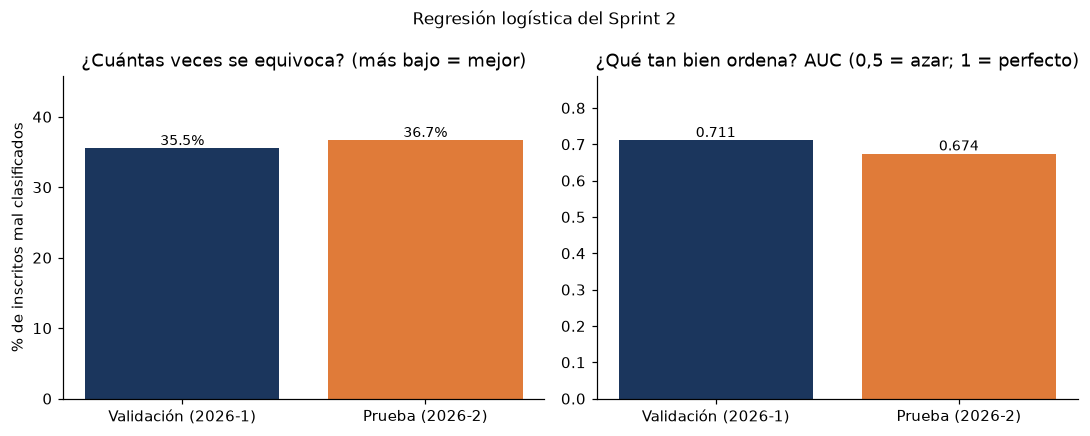


La regresión logística se equivoca en el 36.7% de los inscritos de 2026-2 (AUC 0.674). Este es el punto de comparación del Sprint 3.


In [29]:
V = mo.VARIABLES_MATRICULA
ent = flujo.conjunto(d, "ENTRENAMIENTO")
logistica = mo.construir_pipeline("logistica", cfg["modelado"]["sprint2_logistica"], V, cfg["modelado"]["semilla"]).fit(
    mo.preparar_X(ent, ref, V), ent["matriculado"].astype(int))
coef = pd.Series(logistica.named_steps["modelo"].coef_[0], index=logistica.named_steps["preparacion"].get_feature_names_out())
print("Los 10 coeficientes más grandes (variables estandarizadas; positivo = sube la probabilidad):")
display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10).round(3).rename("β").to_frame())
resultados = {}
for conj in ["VALIDACION", "PRUEBA"]:
    X = flujo.conjunto(d, conj)
    resultados[conj] = mo.metricas(X["matriculado"], logistica.predict_proba(mo.preparar_X(X, ref, V))[:, 1])
metr = pd.DataFrame(resultados).T.astype(float)
display(metr[["n", "error_pct", "auc_roc", "brier"]].round(3))
ver(gr.error_logistica(metr))
b = resultados["PRUEBA"]
print(f"\nLa regresión logística se equivoca en el {b['error_pct']:.1f}% de los inscritos de 2026-2 (AUC {b['auc_roc']:.3f}). "
      "Este es el punto de comparación del Sprint 3.")

**FIN DEL SPRINT 2**

---
**COMIENZA EL SPRINT 3** · entrega del jueves 5 de noviembre de 2026 · archivos del sprint en `sprints/sprint_3_modelado/`

# Sprint 3 — Modelado: la regresión logística con el NLP de la entrevista, frente a Poisson, binomial negativa, Random Forest y XGBoost
**Pedido del docente (Semana 3):** *un modelo de Machine Learning que ya haga predicciones* y una tabla comparativa
sencilla: *"El cálculo de la Semana 2 tenía un error del X%, mientras que este modelo tiene un error del Y%"*.

El proyecto predice **si el inscrito se matricula**. El Sprint 2 dejó una regresión logística sin ajustar y el
**puntaje vocacional NLP** (lo que dicen las palabras del aspirante en la entrevista). Aquí la logística se mejora con
ese puntaje y con el ajuste de sus hiperparámetros, y se compara con dos regresiones de conteo (Poisson y binomial
negativa) y con dos modelos de árboles (Random Forest y XGBoost).

| Sección | Contenido |
|---|---|
| 1 | Variables de entrada (sin fuga de datos) |
| 2 | Ajuste de hiperparámetros con validación temporal |
| 3 | Comparación final en la prueba 2026-2 |
| 4 | Modelos finales y tabla de predicciones (bloque 3 del tablero) |

## 1. Variables de entrada
Solo se usan datos que existen **antes** de la decisión que se predice. Por ejemplo, los documentos entregados o la
forma de financiación no entran: se conocen al matricularse y serían fuga de datos.
Se agregan dos variables simples: `icfes_al_cuadrado`, para que la regresión logística pueda captar la "U invertida"
del Saber 11, y `semestre_2`, el ingreso a mitad de año.

La entrevista entra de dos formas: `puntaje_vocacional` (el del entrevistador, como en el Sprint 2) y
`puntaje_vocacional_nlp` (el que el modelo NLP del Sprint 2 lee en las palabras del aspirante). En ambas, 0 = sin
entrevista, y `entrevista_realizada` distingue ese caso.

Dos variables binarias nuevas (actualización de becas y apoyos de Admisiones):
- `tiene_descuento`: llega con un descuento institucional (familiar de estudiante, egresado o personal). Se suma a la
  beca con un tope del 50%; quien lo tiene ya conoce la Universidad.
- `aplica_icetex`: pidió el crédito ICETEX (Plan Talento STEM) **y** su Saber 11 alcanza el mérito mínimo que ICETEX
  publica para el municipio del colegio.

In [30]:
V, V2 = mo.VARIABLES_MATRICULA_NLP, mo.VARIABLES_MATRICULA      # Sprint 3 (con NLP) · Sprint 2 (sin NLP)
display(pd.DataFrame([(tipo, ", ".join(cols)) for tipo, cols in V.items()], columns=["tipo", "variables (matrícula)"]))
y = lambda x: x["matriculado"].astype(int)
X = lambda x: mo.preparar_X(x, ref, V)
X2 = lambda x: mo.preparar_X(x, ref, V2)
e, v, t = (flujo.conjunto(d, c) for c in ["ENTRENAMIENTO", "VALIDACION", "PRUEBA"])
ev = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION")
print(f"Entrenamiento {len(e)} · validación {len(v)} · prueba {len(t)} inscritos")

,tipo,variables (matrícula)
0,numericas,"punt_global, icfes_al_cuadrado, edad_al_inscri..."
1,binarias,"entrevista_realizada, apoyo_foes, elegible_foe..."
2,categoricas,"programa, genero, canal, beca, tipo_colegio, r..."


Entrenamiento 1310 · validación 504 · prueba 761 inscritos


## 2. Ajuste de hiperparámetros con validación temporal
**Las tres regresiones** usan la misma combinación lineal de las variables, $\eta = \beta_0 + x^\top\beta$, y cambian
en cómo la convierten en probabilidad de matrícula:

| Modelo | Probabilidad de matrícula | Supuesto |
|---|---|---|
| Regresión logística | $p = \dfrac{1}{1 + e^{-\eta}}$ | $y \sim \text{Bernoulli}(p)$ |
| Regresión de Poisson | $\mu = e^{\eta}$, $\;p = \min(\mu, 1)$ | $y \sim \text{Poisson}(\mu)$, varianza $= \mu$ |
| Binomial negativa (NB2) | $\mu = e^{\eta}$, $\;p = \min(\mu, 1)$ | varianza $= \mu + \alpha\mu^2$; si $\alpha \to 0$ es Poisson |

Poisson y binomial negativa son modelos de **conteo**: aquí cada inscrito es un conteo de 0 o 1 matrícula ("Poisson
modificada"). La binomial negativa estima además la sobredispersión $\alpha$.

Cada modelo tiene "perillas" (hiperparámetros): en la regresión logística, la regularización C y el tipo de
penalización (L2 achica todos los pesos; L1 puede dejar en cero las variables que no aportan); en Poisson y binomial
negativa, la penalización L2 $\alpha_{L2}$; la profundidad de los árboles en Random Forest; la tasa de aprendizaje en
XGBoost. Cada combinación se **entrena con 2024-1 a 2025-2 y se
mide en 2026-1**. Se elige la de menor **log-loss**,
$\;-\frac{1}{n}\sum_i \left[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\right]$, que castiga más las probabilidades seguras
que salen mal.
Si un modelo más simple queda a menos de 0,002 del mejor, se prefiere el simple (navaja de Occam).

**Control:** la misma búsqueda de la logística, pero **sin** el puntaje NLP. Así se mide cuánto aporta el texto de la
entrevista, separado del ajuste de hiperparámetros.

In [31]:
COMPLEJIDAD = ["logistica", "poisson", "binomial_negativa", "random_forest", "xgboost"]
busquedas = {tipo: mo.ajustar_temporal(tipo, cfg, X(e), y(e), X(v), y(v), V) for tipo in COMPLEJIDAD}
for tipo, b in busquedas.items():
    print(f"\n{tipo}: {len(b)} combinaciones probadas; las 3 mejores en validación 2026-1")
    display(b.drop(columns="parametros").head(3).round(4))
mejores = {tipo: b.iloc[0] for tipo, b in busquedas.items()}
sin_nlp = mo.ajustar_temporal("logistica", cfg, X2(e), y(e), X2(v), y(v), V2)
print(f"\nControl sin NLP: mejor log-loss {sin_nlp.iloc[0]['log_loss_validacion']:.4f} {sin_nlp.iloc[0]['parametros']} · "
      f"con NLP: {mejores['logistica']['log_loss_validacion']:.4f} {mejores['logistica']['parametros']}")
minimo = min(m["log_loss_validacion"] for m in mejores.values())
elegido = next(tp for tp in COMPLEJIDAD if mejores[tp]["log_loss_validacion"] <= minimo + 0.002)
print(f"\nModelo elegido por validación: {elegido} {mejores[elegido]['parametros']}")


logistica: 8 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_C,param_l1_ratio,param_solver,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,logistica,0.100,0.000,saga,0.618,0.722,0.214,34.524
1,logistica,0.010,0.000,saga,0.621,0.720,0.216,34.325
2,logistica,0.100,1.000,saga,0.621,0.721,0.216,35.318



poisson: 4 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_alpha,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,poisson,0.100,0.635,0.725,0.213,32.937
1,poisson,0.010,0.658,0.725,0.213,32.540
2,poisson,0.001,0.707,0.724,0.215,32.540



binomial_negativa: 4 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_alpha,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,binomial_negativa,0.100,0.635,0.725,0.213,32.937
1,binomial_negativa,0.010,0.658,0.725,0.213,32.540
2,binomial_negativa,0.001,0.706,0.724,0.215,32.738



random_forest: 16 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_max_depth,param_min_samples_leaf,param_max_features,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,random_forest,8.000,5,sqrt,0.627,0.712,0.219,36.706
1,random_forest,6.000,5,sqrt,0.627,0.713,0.219,36.309
2,random_forest,4.000,5,0.500,0.628,0.709,0.220,36.508



xgboost: 12 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_n_estimators,param_max_depth,param_learning_rate,param_min_child_weight,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,xgboost,200,2,0.030,5,0.623,0.712,0.217,35.318
1,xgboost,400,2,0.030,5,0.629,0.707,0.220,35.714
2,xgboost,200,3,0.030,5,0.633,0.701,0.222,36.706



Control sin NLP: mejor log-loss 0.6232 {'C': 0.1, 'l1_ratio': 0.0, 'solver': 'saga'} · con NLP: 0.6175 {'C': 0.1, 'l1_ratio': 0.0, 'solver': 'saga'}

Modelo elegido por validación: logistica {'C': 0.1, 'l1_ratio': 0.0, 'solver': 'saga'}


**Lectura.**
- Con el puntaje NLP, la log-loss de la logística en la validación baja claramente frente al control sin NLP: las
  palabras del aspirante aportan información que el puntaje del entrevistador no tiene.
- La regresión logística gana a los árboles: la relación entre las variables y la matrícula es casi lineal en log-odds,
  y en ese caso los árboles no tienen patrones complejos que aprovechar y corren más riesgo de sobreajustarse.
- Poisson y binomial negativa quedan por detrás: con un enlace log la probabilidad crece sin techo y hay que cortarla
  en 1, así que se ajustan peor a los aspirantes con probabilidad alta. La binomial negativa estima $\alpha$ casi 0
  (una matrícula es 0 o 1: no hay sobredispersión) y da lo mismo que Poisson.
- Ojo: la matrícula de estos datos se simuló con un modelo logístico (supuesto S-15) y el texto con el supuesto S-49;
  con entrevistas y matrículas reales la comparación se repite y puede cambiar.

## 3. Comparación final en la prueba 2026-2
Cada modelo se reentrena con entrenamiento + validación y se evalúa **una sola vez** en 2026-2, un periodo que no se
usó para elegir nada. La logística del Sprint 2 (C = 1, sin ajuste ni NLP) y el control sin NLP también se reentrenan
así, para compararlos en igualdad de condiciones.
- **Error %:** inscritos mal clasificados con umbral de 50%.
- **AUC:** probabilidad de que el modelo ponga a un matriculado por encima de un no matriculado; 0,5 es azar.
- **Brier:** error cuadrático de la probabilidad; más bajo es mejor.

In [32]:
semilla = cfg["modelado"]["semilla"]
probs = {"Regresión logística (Sprint 2)": mo.construir_pipeline("logistica", cfg["modelado"]["sprint2_logistica"], V2, semilla)
                                             .fit(X2(ev), y(ev)).predict_proba(X2(t))[:, 1],
         "Logística ajustada sin NLP (control)": mo.construir_pipeline("logistica", sin_nlp.iloc[0]["parametros"], V2, semilla)
                                                  .fit(X2(ev), y(ev)).predict_proba(X2(t))[:, 1]}
NOMBRES = {"logistica": "Regresión logística ajustada con NLP", "poisson": "Regresión de Poisson con NLP",
           "binomial_negativa": "Regresión binomial negativa con NLP", "random_forest": "Random Forest", "xgboost": "XGBoost"}
ajustados = {}
for tipo in COMPLEJIDAD:
    ajustados[tipo] = mo.construir_pipeline(tipo, mejores[tipo]["parametros"], V, semilla).fit(X(ev), y(ev))
    probs[NOMBRES[tipo]] = ajustados[tipo].predict_proba(X(t))[:, 1]
res = {n: mo.metricas(y(t), q) for n, q in probs.items()}
comparacion = mo.tabla_metricas(res)
from sklearn.metrics import log_loss
comparacion["log_loss"] = [log_loss(y(t), np.clip(probs[n], 1e-6, 1 - 1e-6)) for n in comparacion.index]
display(comparacion[["n", "error_pct", "auc_roc", "auc_pr", "brier", "log_loss"]])
print(f"Binomial negativa: α estimado = {ajustados['binomial_negativa'].named_steps['modelo'].dispersion_:.2e}")
# Conteos: cuántos matriculados predice cada modelo (suma de probabilidades) frente a los reales, por estrato y canal
filas = []
for grupo in ("estrato", "canal"):
    real = t.groupby(grupo)["matriculado"].sum()
    for n, q in probs.items():
        pred = pd.Series(q, index=t.index).groupby(t[grupo]).sum()
        filas.append({"agrupación": grupo, "modelo": n, "reales": int(real.sum()), "predichos": round(float(pred.sum()), 1),
                      "error medio por grupo": round(float((pred - real).abs().mean()), 2)})
display(pd.DataFrame(filas))
b, m = res["Regresión logística (Sprint 2)"], res[NOMBRES[elegido]]
dif = mo.diferencia_error(y(t), probs["Regresión logística (Sprint 2)"], probs[NOMBRES[elegido]])
print("\n" + mo.frase_docente(b["error_pct"], m["error_pct"], NOMBRES[elegido], dif, len(t)))
from sklearn.metrics import roc_auc_score
ic = mo.intervalo_bootstrap(y(t), probs[NOMBRES[elegido]], lambda a, q, u: roc_auc_score(a, q))
print(f"AUC del modelo elegido: {m['auc_roc']:.3f} (IC 95% por bootstrap: {ic[0]:.3f} a {ic[1]:.3f})")
c = res["Logística ajustada sin NLP (control)"]
dif_nlp = mo.diferencia_error(y(t), probs["Logística ajustada sin NLP (control)"], probs[NOMBRES["logistica"]])
print(f"Aporte del NLP (misma logística ajustada): error {c['error_pct']:.1f}% → {res[NOMBRES['logistica']]['error_pct']:.1f}% · "
      f"AUC {c['auc_roc']:.3f} → {res[NOMBRES['logistica']]['auc_roc']:.3f} · IC 95% de la diferencia de error: "
      f"{dif_nlp[0]:.1f} a {dif_nlp[1]:.1f} puntos")

,n,error_pct,auc_roc,auc_pr,brier,log_loss
Regresión logística (Sprint 2),761.000,36.662,0.677,0.689,0.227,0.647
Logística ajustada sin NLP (control),761.000,35.217,0.678,0.690,0.226,0.644
Regresión logística ajustada con NLP,761.000,32.720,0.711,0.719,0.216,0.623
Regresión de Poisson con NLP,761.000,35.348,0.696,0.702,0.222,0.651
Regresión binomial negativa con NLP,761.000,35.348,0.696,0.702,0.222,0.651
Random Forest,761.000,37.319,0.680,0.709,0.225,0.640
XGBoost,761.000,35.480,0.699,0.718,0.219,0.628


Binomial negativa: α estimado = 6.14e-06


,agrupación,modelo,reales,predichos,error medio por grupo
0,estrato,Regresión logística (Sprint 2),416,410.200,3.380
1,estrato,Logística ajustada sin NLP (control),416,422.800,3.300
2,estrato,Regresión logística ajustada con NLP,416,417.900,3.340
3,estrato,Regresión de Poisson con NLP,416,420.800,2.710
4,estrato,Regresión binomial negativa con NLP,416,420.800,2.700
5,estrato,Random Forest,416,434.700,3.630
6,estrato,XGBoost,416,431.500,3.170
7,canal,Regresión logística (Sprint 2),416,410.200,3.950
8,canal,Logística ajustada sin NLP (control),416,422.800,4.100
9,canal,Regresión logística ajustada con NLP,416,417.900,4.220



La regresión logística de la Semana 2 tenía un error del 36,7%, mientras que el modelo de la Semana 3 (Regresión logística ajustada con NLP) tiene un error del 32,7% en 761 inscritos de 2026-2, que ningún modelo vio al entrenar. Mejora 3,9 puntos (IC 95% de la diferencia: -6,0 a -1,7).


AUC del modelo elegido: 0.711 (IC 95% por bootstrap: 0.675 a 0.746)
Aporte del NLP (misma logística ajustada): error 35.2% → 32.7% · AUC 0.678 → 0.711 · IC 95% de la diferencia de error: -4.5 a -0.4 puntos


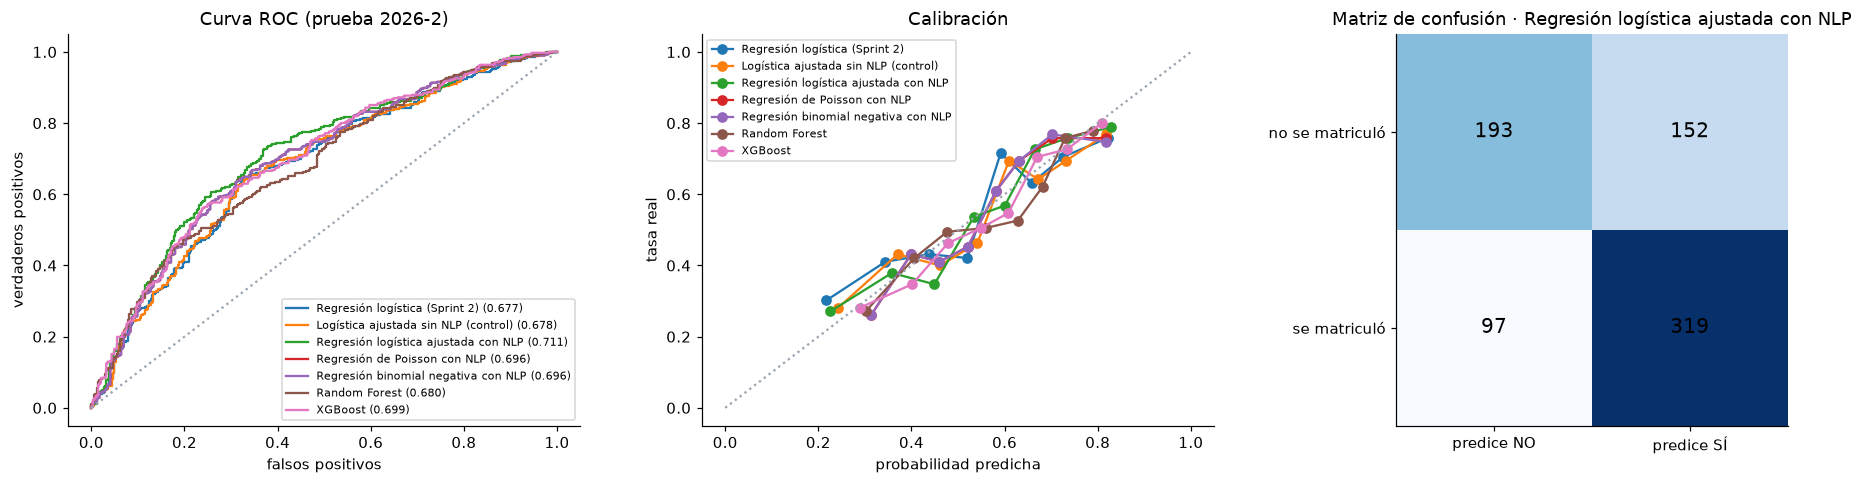

In [33]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, roc_curve
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
for n, q in probs.items():
    fpr, tpr, _ = roc_curve(y(t), q); ejes[0].plot(fpr, tpr, label=f"{n} ({res[n]['auc_roc']:.3f})")
    fr, me = calibration_curve(y(t), q, n_bins=8, strategy="quantile"); ejes[1].plot(me, fr, "o-", label=n)
ejes[0].plot([0, 1], [0, 1], ":", color=GRIS); ejes[0].set(title="Curva ROC (prueba 2026-2)", xlabel="falsos positivos", ylabel="verdaderos positivos")
ejes[1].plot([0, 1], [0, 1], ":", color=GRIS); ejes[1].set(title="Calibración", xlabel="probabilidad predicha", ylabel="tasa real")
for ax in ejes[:2]:
    ax.legend(fontsize=7)
cm = confusion_matrix(y(t), probs[NOMBRES[elegido]] >= 0.5)
ejes[2].imshow(cm, cmap="Blues")
for (i, j), val in np.ndenumerate(cm):
    ejes[2].text(j, i, val, ha="center", va="center", fontsize=13)
ejes[2].set_xticks([0, 1], ["predice NO", "predice SÍ"]); ejes[2].set_yticks([0, 1], ["no se matriculó", "se matriculó"])
ejes[2].set_title(f"Matriz de confusión · {NOMBRES[elegido]}")
plt.tight_layout(); plt.show()

**Lectura.**
- La frase del docente sale de las cifras y de su intervalo bootstrap pareado: solo afirma una mejora si el intervalo
  de la diferencia de error no incluye el 0.
- La logística con NLP tiene el menor error, el mejor AUC y el mejor Brier, pero su ventaja frente a la logística del
  Sprint 2 está **dentro del margen del azar**: con 761 inscritos de prueba no alcanza para afirmar que es mejor.
- El control sin NLP no mejora a la logística del Sprint 2: ajustar hiperparámetros solo no basta. Lo que mueve el
  error y el AUC es el **texto de la entrevista**, aunque el intervalo de esa diferencia también toca el cero.
- Se reporta tal cual: el modelo se eligió con la validación, antes de mirar la prueba, y no se cambia después.
- Aun así se equivoca en cerca de 1 de cada 3 inscritos: la decisión de matricularse depende de factores que no están
  en los datos (familia, otras ofertas, trabajo).
- Su valor está en **ordenar**: a los de mayor probabilidad se les asegura la matrícula y a los indecisos se les hace
  seguimiento (Sprint 5).
- Las curvas de calibración cerca de la diagonal indican que un 60% predicho significa cerca de 60% real.

## 4. Modelos finales y tabla de predicciones (bloque 3 del tablero)
El modelo elegido se reentrena con **todo el histórico** (2024-1 a 2026-2) para predecir la campaña 2027-1. La tabla
`prediccion` (también en Supabase) tiene, por inscrito, la probabilidad de matrícula, el decil y el segmento de
propensión.

In [34]:
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
final = mo.construir_pipeline(elegido, mejores[elegido]["parametros"], V, semilla).fit(X(hist), y(hist))
if elegido == "logistica":                      # qué tanto pesa el puntaje NLP en la regresión logística final
    coef = pd.Series(final.named_steps["modelo"].coef_[0], index=final.named_steps["preparacion"].get_feature_names_out())
    print("Coeficientes de la entrevista (variables estandarizadas):",
          coef[["puntaje_vocacional", "puntaje_vocacional_nlp", "entrevista_realizada"]].round(3).to_dict(),
          f"· variables en cero por L1: {int((coef == 0).sum())} de {len(coef)}")
pm = final.predict_proba(X(d))[:, 1].round(4)
s = cfg["modelado"]["segmentos_propension"]
prediccion = pd.DataFrame({"inscripcion_id": d["inscripcion_id"], "periodo": d["periodo"], "prob_matricula": pm,
                           "segmento_propension": np.select([pm >= s["ALTA"], pm < s["BAJA"]], ["ALTA", "BAJA"], "MEDIA")})
display(prediccion[prediccion["periodo"] == "2027-1"].sort_values("prob_matricula", ascending=False).head(10))
print(prediccion.groupby("periodo")["segmento_propension"].value_counts().unstack().fillna(0).astype(int))

Coeficientes de la entrevista (variables estandarizadas): {'puntaje_vocacional': -0.378, 'puntaje_vocacional_nlp': 0.969, 'entrevista_realizada': -0.276} · variables en cero por L1: 0 de 46


,inscripcion_id,periodo,prob_matricula,segmento_propension
2614,2615,2027-1,0.950,ALTA
1427,1428,2027-1,0.947,ALTA
1462,1463,2027-1,0.936,ALTA
45,46,2027-1,0.935,ALTA
2156,2157,2027-1,0.928,ALTA
1234,1235,2027-1,0.914,ALTA
1087,1088,2027-1,0.907,ALTA
1540,1541,2027-1,0.907,ALTA
2572,2573,2027-1,0.904,ALTA
1426,1427,2027-1,0.903,ALTA


segmento_propension  ALTA  BAJA  MEDIA
periodo                               
2024-1                195    47    116
2024-2                 93    36     78
2025-1                221    69    172
2025-2                142    49     92
2026-1                232   100    172
2026-2                334   133    294
2027-1                221    51    144


## Conclusiones del Sprint 3
1. El modelo de Machine Learning **ya predice** la matrícula de cada inscrito y ordena mejor que el azar.
2. La mejora frente al Sprint 2 viene de **mejores datos**, no de un modelo más complejo: el puntaje vocacional NLP
   (las palabras del aspirante) baja el error y sube el AUC; ajustar hiperparámetros sin él casi no cambia nada.
3. La regresión logística queda por delante de Poisson, la binomial negativa, Random Forest y XGBoost: más simple,
   más exacta y más fácil de explicar. Se elige con evidencia, no por preferencia.
4. Los modelos finales quedan guardados (`sprints/sprint_3_modelado/modelos/`). Los sprints 4 a 6 se actualizarán
   con este modelo cuando se retomen.

**FIN DEL SPRINT 3**

---
**COMIENZA EL SPRINT 4** · entrega del jueves 12 de noviembre de 2026 · archivos del sprint en `sprints/sprint_4_explicabilidad/`

# Sprint 4 — ¿Por qué el modelo toma sus decisiones? (Machine Learning explicable)
**Pedido del docente (Semana 4):** un análisis que responda *"¿Por qué el modelo toma sus decisiones?"* con SHAP o
LIME. Por ejemplo, mostrar que el modelo le da más peso al ICFES que a la edad, con una explicación en español sencillo
de por qué eso tiene sentido para la Universidad.

| Sección | Contenido |
|---|---|
| 1 | Qué es SHAP y cómo se agrupan las variables en conceptos de negocio |
| 2 | Importancia global (modelo elegido vs. XGBoost) |
| 3 | Cómo cambia cada factor: descuento, distancia, Saber 11 y canal |
| 4 | Tres inscritos de la campaña 2027-1: SHAP vs. LIME |
| 5 | Chequeo independiente: importancia por permutación |
| 6 | Chequeos de coherencia y equidad por género |
| 7 | ¿El modelo encontró las causas reales? (comparación con el generador) |
| 8 | Explicaciones para el tablero (bloque 4) |

In [35]:
# Hiperparámetros elegidos en el Sprint 3 (sprints/sprint_3_modelado/modelos/*.json)
PARAMETROS_FINALES = {'matricula': {'parametros': {'C': 0.1, 'l1_ratio': 0.0, 'solver': 'saga'}, 'tipo': 'logistica'},
 'xgboost': {'parametros': {'learning_rate': 0.03,
                            'max_depth': 2,
                            'min_child_weight': 5,
                            'n_estimators': 200}}}

import joblib

MOD = SPRINTS / "sprint_3_modelado" / "modelos"
ruta_fondo = SPRINTS / "sprint_4_explicabilidad" / "resultados" / "fondo_shap.joblib"
fondos = joblib.load(ruta_fondo) if ruta_fondo.exists() else {}
art = {"referencias": ref,
       "modelo_matricula": joblib.load(MOD / "modelo_matricula.joblib")["modelo"],
       "modelo_matricula_xgboost": joblib.load(MOD / "modelo_matricula_xgboost.joblib")["modelo"],
       "logistica_sprint2": joblib.load(MOD / "logistica_sprint2_matricula.joblib")["modelo"]}
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
art["fondo_matricula"] = fondos.get("fondo_matricula", mo.preparar_X(hist, ref, mo.VARIABLES_MATRICULA_NLP).sample(300, random_state=1))
print("Modelos del Sprint 3 cargados:", ", ".join(k for k in art if k.startswith(("modelo", "logistica"))))

Modelos del Sprint 3 cargados: modelo_matricula, modelo_matricula_xgboost, logistica_sprint2


## 1. Qué es SHAP
SHAP reparte la predicción de cada inscrito entre sus variables, como un **reparto justo** entre jugadores de un equipo
(valores de Shapley, teoría de juegos). Para cada inscrito:

`log-odds predicho = valor base (inscrito promedio) + suma de las contribuciones de sus variables`

- Una contribución **positiva** sube la probabilidad de matrícula y una **negativa** la baja.
- Como las contribuciones **se suman**, las variables que miden la misma idea se agrupan en conceptos. Por ejemplo,
  la beca, el descuento y el valor neto forman "Beca y precio".
- En la regresión logística, SHAP es exacto: contribución = coeficiente × (valor − promedio).

In [36]:
import explicabilidad as ex
V = mo.VARIABLES_MATRICULA_NLP          # las del modelo del Sprint 3 (con el puntaje vocacional NLP)
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
X_hist = mo.preparar_X(hist, ref, V)
lm, xgb, fondo = art["modelo_matricula"], art["modelo_matricula_xgboost"], art["fondo_matricula"]
c_lm, base_lm = ex.contribuciones(lm, fondo, X_hist, V)
c_xg, _ = ex.contribuciones(xgb, fondo, X_hist, V)
g_lm, g_xg = ex.agrupar(c_lm, ex.GRUPOS_MATRICULA), ex.agrupar(c_xg, ex.GRUPOS_MATRICULA)
print(f"Valor base (probabilidad de un inscrito promedio): {1 / (1 + np.exp(-base_lm)):.1%}")
# Comprobación de la aditividad: base + suma de contribuciones = predicción del modelo
pred = lm.predict_proba(X_hist)[:, 1]
reconstruida = 1 / (1 + np.exp(-(base_lm + c_lm.sum(axis=1))))
print("Diferencia máxima entre la predicción y base + suma de SHAP:", float(np.abs(pred - reconstruida).max()).__round__(6))
display(pd.DataFrame([(g, ", ".join(v)) for g, v in ex.GRUPOS_MATRICULA.items()], columns=["concepto", "variables"]))

Valor base (probabilidad de un inscrito promedio): 59.8%
Diferencia máxima entre la predicción y base + suma de SHAP: 0.0


,concepto,variables
0,Beca y precio,"beca, pct_descuento_inicial, valor_neto_primer..."
1,Puntaje Saber 11,"punt_global, icfes_al_cuadrado"
2,Distancia al campus,log_distancia
3,Canal de captación,"canal, captado_en_evento"
4,Entrevista vocacional,"entrevista_realizada, puntaje_vocacional, punt..."
5,Apoyo FOES municipal,"apoyo_foes, elegible_foes"
6,Descuento institucional,tiene_descuento
7,Crédito ICETEX,aplica_icetex
8,Estrato y régimen de salud,"estrato, regimen_salud"
9,Programa,programa


## 2. Importancia global
Importancia = el promedio del **valor absoluto** de la contribución, es decir, cuánto mueve un concepto la predicción
en cualquier sentido. Se compara con XGBoost: si dos modelos distintos señalan lo mismo, la conclusión es más sólida.

,regresion_logistica,xgboost,% del total
Beca y precio,0.445,0.306,20.473
Entrevista vocacional,0.374,0.391,17.244
Canal de captación,0.270,0.149,12.430
Puntaje Saber 11,0.190,0.150,8.751
Distancia al campus,0.167,0.133,7.670
Colegio de procedencia,0.156,0.029,7.181
Segmento de mercado,0.122,0.003,5.614
Descuento institucional,0.088,0.008,4.031
Crédito ICETEX,0.084,0.046,3.847
Ingreso a mitad de año,0.068,0.001,3.121


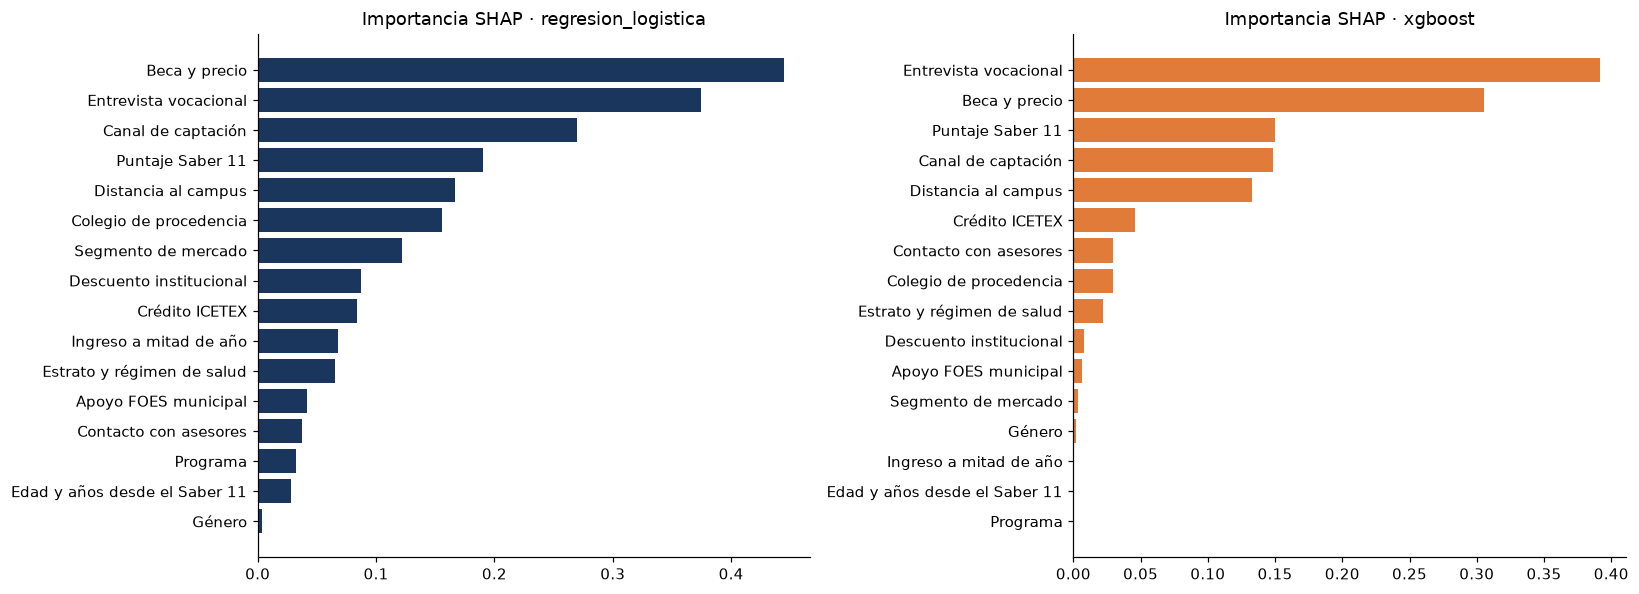

El modelo le da 6.7 veces más peso al puntaje Saber 11 que a la edad.


In [37]:
imp = pd.DataFrame({"regresion_logistica": ex.importancia(g_lm), "xgboost": ex.importancia(g_xg)}).sort_values("regresion_logistica", ascending=False)
imp["% del total"] = 100 * imp["regresion_logistica"] / imp["regresion_logistica"].sum()
display(imp.round(3))
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, col, color in [(ejes[0], "regresion_logistica", AZUL), (ejes[1], "xgboost", NARANJA)]:
    s = imp[col].sort_values(); ax.barh(s.index, s.values, color=color); ax.set_title(f"Importancia SHAP · {col}")
plt.tight_layout(); plt.show()
veces = imp.loc["Puntaje Saber 11", "regresion_logistica"] / imp.loc["Edad y años desde el Saber 11", "regresion_logistica"]
print(f"El modelo le da {veces:.1f} veces más peso al puntaje Saber 11 que a la edad.")

**En español sencillo.** Lo que más decide si un inscrito se matricula es **cuánto le cuesta** (beca y descuento),
seguido de cerca por la **entrevista vocacional** (sobre todo lo que dicen sus propias palabras, el puntaje NLP del
Sprint 2). Le siguen el **canal** por el que llegó, su **puntaje Saber 11**, la **distancia** desde su casa al campus y
el **tipo de colegio**. La edad y el género pesan poco. Tiene sentido para la Universidad: quien muestra una vocación clara se
compromete más, y el precio y la cercanía son barreras reales.

La entrevista se lee como **un solo concepto** (si la presentó, el puntaje del entrevistador y el puntaje NLP). Por
separado se compensan: con las mismas palabras, un puntaje alto del entrevistador deja menos intención por explicar, y
el modelo le da un peso negativo. Sumados, dicen cuánto mueve la entrevista.

## 3. Cómo cambia cada factor

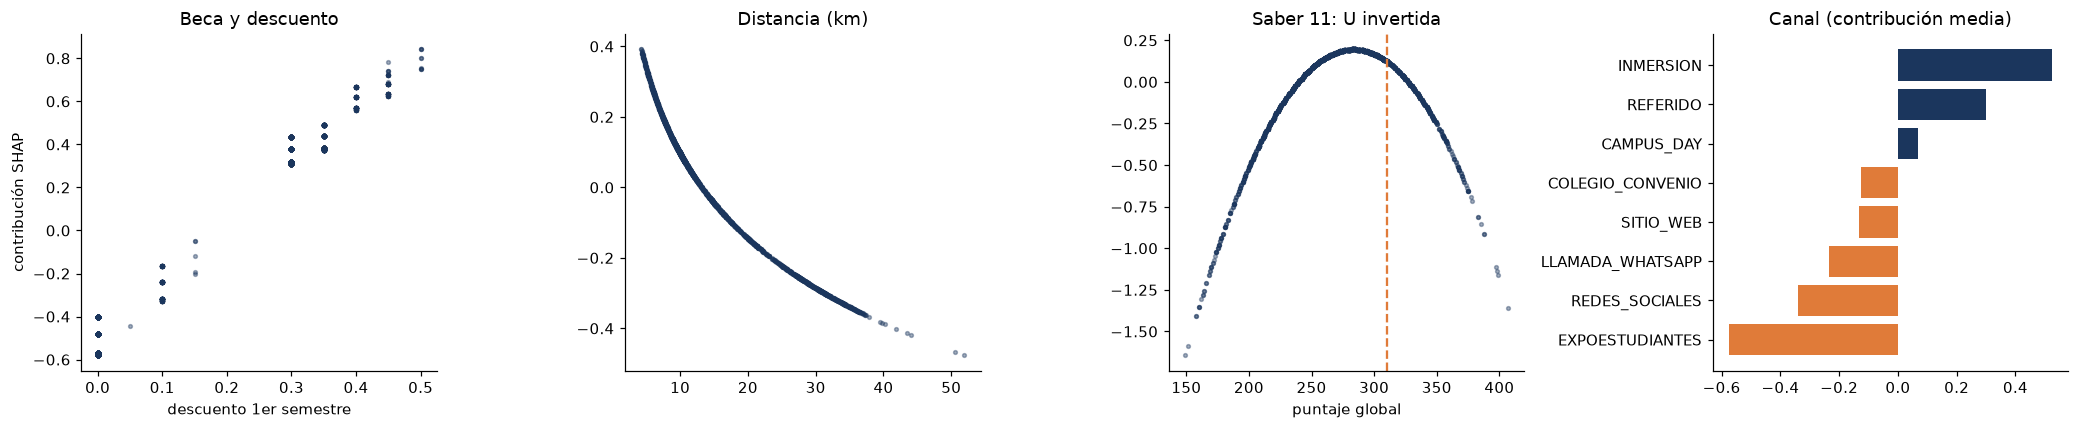

In [38]:
fig, ejes = plt.subplots(1, 4, figsize=(19, 4))
ejes[0].scatter(X_hist["pct_descuento_inicial"], c_lm[["pct_descuento_inicial", "valor_neto_primer_semestre", "beca"]].sum(axis=1), s=6, alpha=0.4, color=AZUL)
ejes[0].set(title="Beca y descuento", xlabel="descuento 1er semestre", ylabel="contribución SHAP")
ejes[1].scatter(np.exp(X_hist["log_distancia"]), c_lm["log_distancia"], s=6, alpha=0.4, color=AZUL); ejes[1].set(title="Distancia (km)")
ejes[2].scatter(X_hist["punt_global"], c_lm[["punt_global", "icfes_al_cuadrado"]].sum(axis=1), s=6, alpha=0.4, color=AZUL)
ejes[2].axvline(310, color=NARANJA, ls="--"); ejes[2].set(title="Saber 11: U invertida", xlabel="puntaje global")
canal = (c_lm["canal"] + c_lm["captado_en_evento"]).groupby(X_hist["canal"]).mean().sort_values()
ejes[3].barh(canal.index, canal.values, color=[NARANJA if x < 0 else AZUL for x in canal.values]); ejes[3].set(title="Canal (contribución media)")
plt.tight_layout(); plt.show()

## 4. Tres inscritos de la campaña 2027-1: SHAP vs. LIME
LIME explica **un** inscrito ajustando un modelo lineal sencillo con miles de "vecinos" simulados parecidos a él. Si
SHAP y LIME señalan los mismos factores, la explicación es más confiable.

In [39]:
camp = flujo.conjunto(d, "CAMPANA")
X_camp = mo.preparar_X(camp, ref, V)
prob_camp = pd.Series(lm.predict_proba(X_camp)[:, 1], index=camp.index)
casos = {n: (prob_camp - prob_camp.quantile(q)).abs().idxmin() for n, q in [("ALTA", 0.9), ("MEDIA", 0.5), ("BAJA", 0.1)]}
c_camp, _ = ex.contribuciones(lm, fondo, X_camp.loc[list(casos.values())], V)
g_camp = ex.agrupar(c_camp, ex.GRUPOS_MATRICULA)
for nombre, idx in casos.items():
    print(f"\n=== Propensión {nombre} · inscrito {int(camp.loc[idx, 'inscripcion_id'])} · probabilidad {prob_camp[idx]:.0%}")
    top = g_camp.loc[idx].reindex(g_camp.loc[idx].abs().sort_values(ascending=False).index)[:4]
    print("SHAP (conceptos):", "; ".join(f"{k} {v:+.2f}" for k, v in top.items()))
    lime = ex.explicar_lime(lm, X_hist.sample(800, random_state=2), X_camp.loc[[idx]], V, n_variables=5)
    print("LIME (reglas locales):", "; ".join(f"{k} {w:+.3f}" for k, w in lime))


=== Propensión ALTA · inscrito 2033 · probabilidad 84%
SHAP (conceptos): Colegio de procedencia +0.46; Beca y precio +0.38; Entrevista vocacional +0.38; Distancia al campus +0.27
LIME (reglas locales): puntaje_vocacional_nlp > 3.95 +0.249; aplica_icetex <= 0.00 -0.087; valor_neto_primer_semestre <= 3194100.00 +0.081; tiene_descuento <= 0.00 -0.079; 3.00 < puntaje_vocacional <= 4.00 -0.054

=== Propensión MEDIA · inscrito 2162 · probabilidad 62%
SHAP (conceptos): Beca y precio -0.58; Canal de captación +0.52; Distancia al campus -0.30; Segmento de mercado +0.28


LIME (reglas locales): 3.21 < puntaje_vocacional_nlp <= 3.95 +0.127; canal=INMERSION +0.117; aplica_icetex <= 0.00 -0.089; log_distancia > 3.05 -0.084; valor_neto_primer_semestre > 4658000.00 -0.074

=== Propensión BAJA · inscrito 1472 · probabilidad 32%
SHAP (conceptos): Beca y precio -0.58; Puntaje Saber 11 -0.51; Distancia al campus -0.31; Entrevista vocacional +0.25


LIME (reglas locales): puntaje_vocacional <= 2.00 +0.129; aplica_icetex <= 0.00 -0.094; icfes_al_cuadrado > 1.49 -0.090; log_distancia > 3.05 -0.082; valor_neto_primer_semestre > 4658000.00 -0.077


## 5. Chequeo independiente: importancia por permutación
Se **desordena** un concepto en la prueba 2026-2, dejando lo demás igual, y se mide cuánto cae el AUC del modelo. No
usa SHAP: es otra forma de preguntar de qué depende el modelo.

In [40]:
ev, t = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION"), flujo.conjunto(d, "PRUEBA")
pm = PARAMETROS_FINALES["matricula"]     # el modelo elegido, reentrenado sin la prueba para medir en ella
lm_ev = mo.construir_pipeline(pm["tipo"], pm["parametros"], V, cfg["modelado"]["semilla"]).fit(
    mo.preparar_X(ev, ref, V), ev["matriculado"].astype(int))
perm = ex.importancia_permutacion(lm_ev, mo.preparar_X(t, ref, V), t["matriculado"].astype(int), ex.GRUPOS_MATRICULA)
display(perm.head(8).round(4))

,concepto,caida_auc,de_caida
0,Entrevista vocacional,0.072,0.010
1,Beca y precio,0.071,0.009
2,Puntaje Saber 11,0.028,0.004
3,Canal de captación,0.021,0.008
4,Distancia al campus,0.015,0.006
5,Colegio de procedencia,0.005,0.002
6,Crédito ICETEX,0.005,0.003
7,Descuento institucional,0.003,0.001


## 6. Chequeos de coherencia y equidad
¿El modelo se comporta como se espera? Cada afirmación se comprueba con los datos. La equidad se revisa de dos formas: el género debe pesar poco, y el
modelo no debe crear una diferencia entre hombres y mujeres que no exista en los datos reales.

In [41]:
coh = ex.chequeos_coherencia(X_hist, c_lm, g_lm, lm.predict_proba(X_hist)[:, 1], hist["matriculado"])
display(coh)
print(f"Cumple {int(coh['cumple'].sum())} de {len(coh)} chequeos")

,chequeo,cumple,evidencia
0,Más descuento → más probabilidad de matrícula,True,correlación entre descuento y su contribución ...
1,Las becas pesan a favor frente a no tener beca,True,contribución media de la beca: MI_VOCACION +0....
2,Más distancia → menos probabilidad,True,correlación entre distancia y su contribución < 0
3,Saber 11 en U invertida: los puntajes muy alto...,True,"contribución media por banda: < 230 -0.41, 230..."
4,La entrevista vocacional pesa a favor,True,contribución media del concepto con entrevista...
5,Más vocación en sus palabras (puntaje NLP) → m...,True,correlación entre el puntaje NLP y su contribu...
6,El género NO domina las decisiones,True,puesto 16 de 16; importancia 0.004 vs. 0.445 d...
7,Paridad por género: el modelo no crea una brec...,True,brecha predicha F-M 0.007 vs. brecha real 0.007


Cumple 8 de 8 chequeos


## 7. ¿El modelo encontró las causas reales?
Como los datos son sintéticos, se conocen los efectos **verdaderos** con los que se generó la matrícula
(configuración del generador, `generador.matricula`). Es una prueba que con datos reales no se puede hacer: ¿la
explicación recupera la dirección de cada causa real?

In [42]:
gen = ex.comparar_con_generador(X_hist, c_lm, cfg)
display(gen)
print(f"Coinciden {int(gen['coincide'].sum())} de {len(gen)} efectos.")

,efecto,verdadero (generador),según SHAP,coincide
0,Descuento (beca),positivo (β = 3.0),positivo,True
1,Distancia al campus,negativo (β = -0.35),negativo,True
2,Saber 11 (término cuadrático),U invertida (β = -0.25),U invertida,True
3,Entrevista vocacional,positivo (β = 0.6),positivo,True
4,Apoyo FOES,positivo (β = 0.5),positivo,True
5,Programa SSIA,positivo (β = 0.1),positivo,True
6,Ingreso a mitad de año,negativo (β = -0.1),negativo,True
7,Canal (orden de los 8 canales),inmersión > referido > campus day/convenio > w...,correlación de Spearman con el orden real = 0.97,True
8,Estrato (orden de los 6 estratos),estrato 1 el más bajo; 4 el más alto,correlación de Spearman con el orden real = 0.32,False
9,Género (sin efecto real),ninguno (β = 0),importancia 0.004 log-odds,True


Coinciden 9 de 10 efectos.


**Lectura.** Los efectos grandes (beca, distancia, U invertida del Saber 11, entrevista, FOES, canal) se recuperan bien.
Falla el orden del estrato (pocos casos en estratos 5 y 6). El promedio del colegio ya no se revisa: dejó de ser una
variable del modelo. **Lección:** una explicación muestra lo que el modelo aprendió, no garantiza la causa.

## 8. Explicaciones para el tablero
Para cada inscrito se generan los **3 factores** que más mueven su probabilidad de matrícula, en español. Esta es la
tabla `explicacion_prediccion` (bloque 4 del tablero).

In [43]:
X_todos = mo.preparar_X(d, ref, V)
c_todos, _ = ex.contribuciones(lm, fondo, X_todos, V)
explicacion = ex.top_factores(ex.agrupar(c_todos, ex.GRUPOS_MATRICULA), X_todos, d["inscripcion_id"])
print(f"\nTabla del bloque 4: {len(explicacion):,} filas (3 por inscrito). Ejemplo:")
display(explicacion.head(6))


Tabla del bloque 4: 8,973 filas (3 por inscrito). Ejemplo:


,inscripcion_id,orden,factor,direccion,contribucion_log_odds,texto
0,1,1,Colegio de procedencia,SUBE,0.460,Colegio de procedencia (colegio privado): aume...
1,1,2,Beca y precio,SUBE,0.382,"Beca y precio (beca Saber 11, descuento 35%): ..."
2,1,3,Distancia al campus,SUBE,0.271,Distancia al campus (vive a 6 km por vía): aum...
3,2,1,Beca y precio,BAJA,-0.481,"Beca y precio (beca Ninguna, descuento 0%): re..."
4,2,2,Entrevista vocacional,BAJA,-0.321,Entrevista vocacional (puntaje vocacional 2; s...
5,2,3,Canal de captación,BAJA,-0.234,Canal de captación (llegó por llamada whatsapp...


## Conclusiones del Sprint 4
1. **Por qué decide así:** la beca y el precio explican más de una cuarta parte de las decisiones. Les siguen la
   entrevista, el Saber 11 (en U invertida), la distancia y el canal. La edad y el género pesan poco.
2. **Coherencia:** el modelo pasa los chequeos de coherencia y no crea brechas por género.
3. **Rigor:** SHAP recupera la mayoría de las causas reales del generador, y la importancia por permutación lo
   confirma.
4. **Para el tablero:** cada inscrito tiene sus 3 razones principales en español (`explicacion_prediccion`).

**FIN DEL SPRINT 4**

---
**COMIENZA EL SPRINT 5** · entrega del jueves 19 de noviembre de 2026 · archivos del sprint en `sprints/sprint_5_validacion_impacto/`

# Sprint 5 — Validación con datos no vistos e impacto en matrículas
**Pedido del docente (Semana 5):** *tomar un pequeño grupo de datos que el modelo no haya visto antes y evaluar si
acierta o falla*, con *un cálculo estimado de cómo esto ayuda a la Universidad a no perder dinero o estudiantes*.
Además, simular escenarios que muestren cómo el modelo optimiza la captación y la asignación de recursos.

| Sección | Contenido |
|---|---|
| 1 | Se abre el resultado sellado de la campaña 2027-1 |
| 2 | ¿Acierta o falla? |
| 3 | Escenario 1: ¿a quién llamar primero? |
| 4 | Escenario 2: Expo Estudiantes |
| 5 | Sensibilidad de los supuestos y acciones por segmento |

## 1. Se abre el "sobre sellado"
Desde la Semana 1, el resultado de matrícula de los inscritos de la campaña 2027-1 quedó guardado aparte y **no se usó**
para entrenar, ajustar ni elegir modelos. Ahora se lee de Supabase (tabla `resultado_campana_2027_1`, solo lectura);
sin clave de Supabase, de su copia en el repositorio (en Colab, la de GitHub).

> Aclaración honesta: es un resultado **sintético**, generado con las mismas reglas que el resto de la base. Con datos
> reales de Admisiones, este mismo cuaderno se vuelve a ejecutar.

In [44]:
import datos
import impacto as im
sellado, origen = datos.cargar("resultado_campana_2027_1", "auto")   # Supabase, o su copia (repositorio o GitHub)
camp = flujo.conjunto(d, "CAMPANA").merge(sellado, on="inscripcion_id", how="left", validate="one_to_one")
print(f"Resultado 2027-1 leído de: {origen} · {len(camp)} inscritos · se matricularon {int(camp['matriculado_real'].sum())}")

Resultado 2027-1 leído de: Supabase (API de solo lectura) · 416 inscritos · se matricularon 246


## 2. ¿Acierta o falla?

,n,error_pct,auc_roc,brier,precision,recall
Modelo elegido (regresión logística con NLP),416.000,33.894,0.697,0.213,0.685,0.789
XGBoost,416.000,34.135,0.687,0.216,0.696,0.752
Regresión logística (Sprint 2),416.000,35.337,0.665,0.222,0.671,0.789


Error del modelo elegido: 33.9% (IC 95%: 29.6% a 38.7%)
Diferencia con la logística del Sprint 2: IC 95% de -4.1 a 1.2 puntos (incluye el 0: rinden igual).


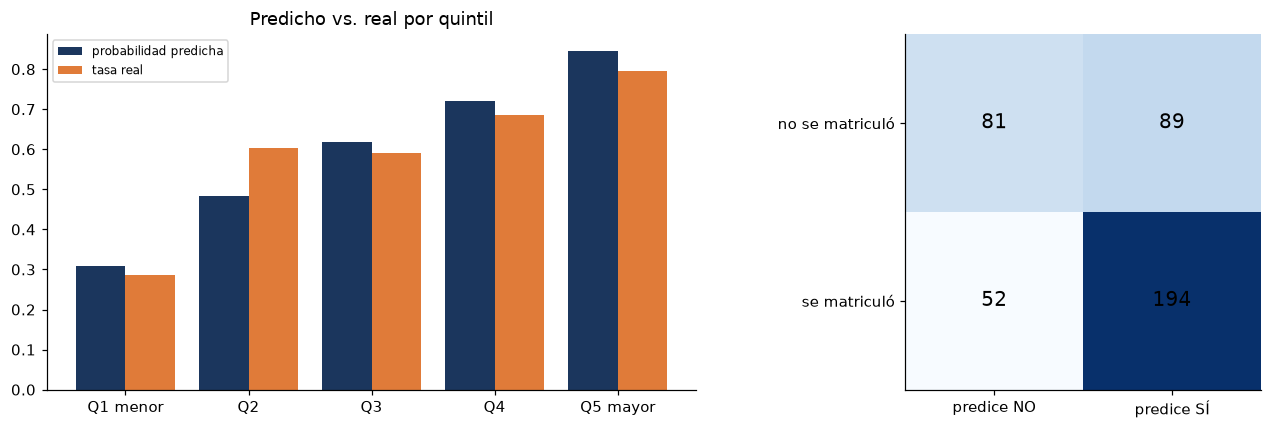

,inscritos,prob_media,tasa_real
grupo,,,
Q1 menor,84,0.309,0.286
Q2,83,0.484,0.602
Q3,83,0.618,0.590
Q4,83,0.720,0.687
Q5 mayor,83,0.845,0.795


In [45]:
from sklearn.metrics import confusion_matrix, roc_auc_score
V, V2 = mo.VARIABLES_MATRICULA_NLP, mo.VARIABLES_MATRICULA   # elegido y XGBoost con NLP · Sprint 2 sin NLP
Xc, Xc2, yc = mo.preparar_X(camp, ref, V), mo.preparar_X(camp, ref, V2), camp["matriculado_real"].astype(int)
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
probs = {"Modelo elegido (regresión logística con NLP)": art["modelo_matricula"].predict_proba(Xc)[:, 1],
         "XGBoost": art["modelo_matricula_xgboost"].predict_proba(Xc)[:, 1],
         "Regresión logística (Sprint 2)": art["logistica_sprint2"].predict_proba(Xc2)[:, 1]}
res = {n: mo.metricas(yc, q) for n, q in probs.items()}
display(mo.tabla_metricas(res)[["n", "error_pct", "auc_roc", "brier", "precision", "recall"]])
p_final = probs["Modelo elegido (regresión logística con NLP)"]
ic = mo.intervalo_bootstrap(yc, p_final, lambda a, q, u: 100 * ((q >= u) != a).mean())
print(f"Error del modelo elegido: {res['Modelo elegido (regresión logística con NLP)']['error_pct']:.1f}% (IC 95%: {ic[0]:.1f}% a {ic[1]:.1f}%)")
dif = mo.diferencia_error(yc, probs["Regresión logística (Sprint 2)"], p_final)
print(f"Diferencia con la logística del Sprint 2: IC 95% de {dif[0]:.1f} a {dif[1]:.1f} puntos"
      + (" (incluye el 0: rinden igual)." if dif[0] <= 0 <= dif[1] else "."))
camp["prob"] = p_final
q = camp.assign(grupo=pd.qcut(camp["prob"].rank(method="first"), 5, labels=["Q1 menor", "Q2", "Q3", "Q4", "Q5 mayor"])) \
        .groupby("grupo", observed=True).agg(inscritos=("prob", "size"), prob_media=("prob", "mean"), tasa_real=("matriculado_real", "mean"))
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(q))
ejes[0].bar(x - 0.2, q["prob_media"], 0.4, color=AZUL, label="probabilidad predicha")
ejes[0].bar(x + 0.2, q["tasa_real"], 0.4, color=NARANJA, label="tasa real")
ejes[0].set_xticks(x, q.index); ejes[0].legend(fontsize=8); ejes[0].set_title("Predicho vs. real por quintil")
cm = confusion_matrix(yc, p_final >= 0.5); ejes[1].imshow(cm, cmap="Blues")
for (i, j), val in np.ndenumerate(cm):
    ejes[1].text(j, i, val, ha="center", va="center", fontsize=13)
ejes[1].set_xticks([0, 1], ["predice NO", "predice SÍ"]); ejes[1].set_yticks([0, 1], ["no se matriculó", "se matriculó"])
plt.tight_layout(); plt.show()
display(q.round(3))

**Lectura.** El modelo falla en cerca de 1 de cada 3 casos individuales, pero **ordena**: el quintil de mayor
probabilidad se matricula más del doble que el de menor. Para la Universidad, lo valioso es saber **a quién
dedicarle el esfuerzo**, no adivinar a cada persona.

## 3. Escenario 1: ¿a quién llamar primero?
Los asesores solo alcanzan a hacer seguimiento intensivo al 30% de los inscritos (supuesto). La llamada ayuda poco
a quien ya decidió y más al indeciso (supuesto):

`efecto(p) = 0,10 × 4 × p × (1 − p)`, es decir, +10 puntos si p = 0,5 y casi 0 si p está cerca de 0 o de 1.

Valor de una matrícula adicional = precio neto del 1er semestre con su beca (tarifas oficiales). No se calculan costos
porque no hay datos de cuánto cuesta el seguimiento.

In [46]:
s = cfg["impacto"]["seguimiento"]
e1 = im.escenario_seguimiento(camp["prob"], camp["valor_neto_primer_semestre"], s["capacidad_pct"], s["efecto_maximo"])
display(e1.round(1))
print(f"Llamar a los indecisos (modelo) deja {e1.iloc[2]['matriculas_adicionales'] - e1.iloc[0]['matriculas_adicionales']:.1f} matrículas y "
      f"${e1.iloc[2]['ingreso_primer_semestre_cop'] - e1.iloc[0]['ingreso_primer_semestre_cop']:,.0f} ".replace(",", ".")
      + "más que llamar al azar en una campaña; llamar primero a los de mayor probabilidad es lo peor.")

,estrategia,inscritos_con_seguimiento,matriculas_adicionales,ingreso_primer_semestre_cop
0,Al azar (sin modelo),125,10.200,"42,090,888.600"
1,Mayor probabilidad primero,125,7.500,"25,659,015.100"
2,Indecisos primero (modelo),125,12.300,"53,315,204.000"


Llamar a los indecisos (modelo) deja 2.1 matrículas y $11.224.315 más que llamar al azar en una campaña; llamar primero a los de mayor probabilidad es lo peor.


## 4. Escenario 2: Expo Estudiantes
Se aplica el mismo seguimiento priorizado a los inscritos que llegaron por la Expo en cada campaña histórica y se mide
cuántas **matrículas más** se esperan. No se calcula el costo por matriculado porque no hay datos de la inversión en el
evento.

In [47]:
expo = hist[hist["canal"] == "EXPOESTUDIANTES"].copy()
expo["prob"] = art["modelo_matricula"].predict_proba(mo.preparar_X(expo, ref, V))[:, 1]
filas = []
for per, g in expo.groupby("periodo"):
    reales = int(g["matriculado"].astype(int).sum())
    t = im.escenario_seguimiento(g["prob"], g["valor_neto_primer_semestre"], s["capacidad_pct"], s["efecto_maximo"])
    filas.append({"campaña": per, "inscritos Expo": len(g), "matriculados": reales,
                  "matrículas adicionales": t.iloc[2]["matriculas_adicionales"]})
display(pd.DataFrame(filas).round(1))
seg = expo.assign(m=expo["matriculado"].astype(float)).groupby("segmento_mercado").agg(inscritos=("m", "size"), tasa=("m", "mean"))
print("Segmentos que mejor convierten cuando llegan por la Expo:")
display(seg.sort_values("tasa", ascending=False).round(3))

,campaña,inscritos Expo,matriculados,matrículas adicionales
0,2024-1,44,17,1.300
1,2025-1,60,26,1.800
2,2026-1,74,30,2.200


Segmentos que mejor convierten cuando llegan por la Expo:


,inscritos,tasa
segmento_mercado,,
"S1: Colegio privado, estrato más alto",64,0.516
"S2: Colegio público, viven cerca del campus",57,0.386
"S4: Aspirantes mayores, puntaje ICFES bajo",15,0.333
"S3: Viven lejos del campus, estrato más bajo",42,0.310


## 5. Sensibilidad y acciones por segmento
Cada supuesto se mueve −50% y +50%, dejando los demás fijos, para ver cuánto cambia el resultado (gráfico de tornado).
El supuesto que más mueve la cifra es el que primero hay que validar con Admisiones.

In [48]:
def matriculas_seguimiento(capacidad_pct, efecto_maximo):
    t = im.escenario_seguimiento(camp["prob"], camp["valor_neto_primer_semestre"], capacidad_pct, efecto_maximo)
    return {"matriculas_con_modelo": float(t.iloc[2]["matriculas_adicionales"])}
sens1 = im.sensibilidad(matriculas_seguimiento, dict(s), list(s), "matriculas_con_modelo")
display(sens1.round(2))
acciones = im.acciones_por_segmento(camp, camp["prob"], cfg["modelado"]["segmentos_propension"])
display(acciones.round(3))

,supuesto,valor_base,resultado_bajo,resultado_base,resultado_alto,rango
0,efecto_maximo,0.100,6.150,12.290,18.440,12.290
1,capacidad_pct,0.300,6.170,12.290,18.080,11.910


,inscritos,propension_media,pct_indecisos,pct_lejos,pct_con_beca,valor_esperado_por_inscrito,accion_sugerida
segmento_mercado,,,,,,,
"S4: Aspirantes mayores, puntaje ICFES bajo",35,0.620,0.457,0.286,0.457,"2,475,204.204",asegurar: proceso de matrícula ágil y recordat...
"S1: Colegio privado, estrato más alto",152,0.636,0.296,0.112,0.599,"2,391,215.412",asegurar: proceso de matrícula ágil y recordat...
"S2: Colegio público, viven cerca del campus",132,0.595,0.348,0.000,0.545,"2,279,139.783",asegurar: proceso de matrícula ágil y recordat...
"S3: Viven lejos del campus, estrato más bajo",97,0.520,0.392,0.887,0.412,"2,120,790.398",asegurar: proceso de matrícula ágil y recordat...


## Conclusiones del Sprint 5
1. Con datos que nunca vio, el modelo **ordena** a los inscritos mucho mejor que el azar (AUC cercano a 0,68). Su error
   individual (cerca de 34%) es unos 3 puntos menor que el de la regresión logística del Sprint 2, pero la diferencia
   todavía cabe en el margen del azar.
2. **Captación:** priorizar a los indecisos da más matrículas e ingreso que llamar al azar, y mucho más que llamar a los
   seguros. En la Expo se esperan algunas matrículas más con el mismo seguimiento.
3. Las cifras dependen de dos supuestos (capacidad de seguimiento y efecto de la llamada). El análisis de sensibilidad
   muestra cuál validar primero. No se incluyen costos porque no hay datos de ellos.

**FIN DEL SPRINT 5**